# Klasifikasi Aksara Jawa (20 kelas): ANN vs CNN vs Transfer Learning
Group Mini Project - Neural Network / Deep Learning

**Dataset:** Javanese Script (Aksara Jawa) Augmented - Kaggle (hannanhunafa), data sekunder
- 20 kelas: ba, ca, da, dha, ga, ha, ja, ka, la, ma, na, nga, nya, pa, ra, sa, ta, tha, wa, ya
- Split bawaan: train 8.400, val 2.400, test 1.200 gambar
- Setiap gambar adalah varian augmentasi (diputar/digeser/di-zoom) dari tulisan tangan asli; test hanya berasal dari 41 tulisan asli

**Alur:** 1) Setup -> 2) Data & EDA (termasuk pembersihan kebocoran) -> 3) Arsitektur -> 4) Eksperimen 3 fase -> 5) Analisis model final -> 6) Group K-Fold -> 7) Ringkasan untuk slide

**Prinsip:** model dipilih berdasarkan **validasi**; data test hanya dipakai untuk laporan akhir.

### Peta notebook -> slide (sesuai soal)
| Slide | Isi | Bagian notebook |
|---|---|---|
| 1-2 | Identitas & jobdesc | (diisi manual) |
| 3 | Deskripsi kasus | Bagian ini |
| 4 | Data, splitting, k-fold | Bagian 2 dan 6 |
| 5 | Arsitektur | Bagian 3 |
| 6 | Learning strategy & tuning | Bagian 4 |
| 7-9 | Hasil eksperimen | Bagian 5 dan 7 |
| 10 | Kesimpulan | Bagian 7 (draf otomatis) |
| 11-12 | URL kode & referensi | (diisi manual) |

### Cara menjalankan
1. Semua hasil disimpan di folder baru `D:\aksara_jawa\output_final`, terpisah dari hasil notebook lama (`output`). Hapus `output_final` hanya jika ingin mengulang dari nol.
2. Pilih kernel `.venv`, lalu **Restart -> Run All**.
3. Semua hasil tersimpan bertahap di `D:\aksara_jawa\output_final`. Jika terputus, cukup **Restart -> Run All** lagi; eksperimen yang sudah selesai otomatis dilewati.

**Perkiraan waktu di CPU (gambar 96x96): 7-9 jam** -> sebaiknya dijalankan semalaman (laptop dicolok, sleep dimatikan). Fase 1 sekitar 1 jam, random search sekitar 3 jam, uji seed sekitar 2-3 jam, Group K-Fold sekitar 1-2 jam. Dengan GPU (Kaggle/Colab) otomatis memakai 224x224 dan jauh lebih cepat.

## 1. Setup

In [26]:
import os, re, glob, time, random, zipfile, json, shutil, tempfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
import sys
print("TensorFlow:", tf.__version__, "| Python:", sys.version.split()[0])
print("GPU:", tf.config.list_physical_devices("GPU"))   # kosong = CPU (notebook otomatis pakai mode CPU)

TensorFlow: 2.21.0 | Python: 3.10.6
GPU: []


In [27]:
# --- Lokasi dataset di komputer (Windows) ---
# Isi D:\aksara_jawa boleh berupa archive.zip ATAU folder train/val/test (keduanya otomatis dikenali).
import shutil
SRC = r"D:\aksara_jawa"
OUT_DIR = os.path.join(SRC, "output_final")        # hasil (results.csv, bobot model) disimpan di sini

def find_root(base):
    for root, dirs, _ in os.walk(base):
        if {"train", "val", "test"} <= set(dirs):
            return root
    return None

def count_images(d):
    return sum(len(fs) for _, _, fs in os.walk(d))

EXPECTED = {"train": 8400, "val": 2400, "test": 1200}    # jumlah pada dataset asli (20 kelas)
def counts(d):
    return {s: count_images(f"{d}/{s}") if os.path.isdir(f"{d}/{s}") else 0 for s in EXPECTED}

assert os.path.isdir(SRC), f"Folder tidak ditemukan: {SRC}"
print("Isi folder sumber:", os.listdir(SRC))

DATA_DIR = find_root(SRC)                    # kasus 1: folder train/val/test sudah ada -> langsung dipakai (tanpa disalin)
if DATA_DIR is None:                         # kasus 2: masih berupa zip -> diekstrak ke D:\aksara_jawa\data
    zips = glob.glob(os.path.join(SRC, "*.zip"))
    if not zips:
        raise FileNotFoundError(f"Tidak ada .zip atau folder train/val/test di {SRC}")
    DATA_DIR = os.path.join(SRC, "data")
    TMP = DATA_DIR + "_tmp"
    shutil.rmtree(TMP, ignore_errors=True)
    with zipfile.ZipFile(zips[0]) as z:
        z.extractall(TMP)
    shutil.move(find_root(TMP), DATA_DIR)    # baru dianggap ada setelah SELESAI penuh
    shutil.rmtree(TMP, ignore_errors=True)

print("DATA_DIR:", DATA_DIR)
print("Jumlah gambar:", counts(DATA_DIR), "| diharapkan:", EXPECTED)
if counts(DATA_DIR) != EXPECTED:
    print("PERINGATAN: jumlah berbeda dari dataset asli. Cek isi folder (mungkin ada file yang belum lengkap).")

Isi folder sumber: ['output', 'output_final', 'predict_test', 'test', 'train', 'val']
DATA_DIR: D:\aksara_jawa
Jumlah gambar: {'train': 8400, 'val': 2400, 'test': 1200} | diharapkan: {'train': 8400, 'val': 2400, 'test': 1200}


In [28]:
# === Simpan otomatis SEMUA grafik ===
# Setiap kali plt.show() dipanggil, grafiknya juga disimpan sebagai PNG ke output_final/figures.
# Folder dikosongkan dulu setiap Run All, jadi isinya selalu versi terbaru.
import matplotlib.pyplot as plt
FIG_DIR = os.path.join(OUT_DIR, "figures")
shutil.rmtree(FIG_DIR, ignore_errors=True)
os.makedirs(FIG_DIR, exist_ok=True)
_fig_no = [0]
if not hasattr(plt, "_show_asli"):            # cegah dibungkus dua kali jika sel ini dijalankan ulang
    plt._show_asli = plt.show

def _judul_grafik(fig):
    if fig._suptitle is not None and fig._suptitle.get_text():
        return fig._suptitle.get_text()
    for ax in fig.axes:
        if ax.get_title():
            return ax.get_title()
    return "grafik"

def _show_dan_simpan(*args, **kwargs):
    for num in plt.get_fignums():
        fig = plt.figure(num)
        _fig_no[0] += 1
        nama = re.sub(r"[^a-z0-9]+", "_", _judul_grafik(fig).lower()).strip("_")[:60] or "grafik"
        fig.savefig(os.path.join(FIG_DIR, f"{_fig_no[0]:02d}_{nama}.png"), dpi=150, bbox_inches="tight")
    hasil = plt._show_asli(*args, **kwargs)
    plt.close("all")                          # tutup supaya grafik yang sama tidak tersimpan dua kali
    return hasil

plt.show = _show_dan_simpan
print("Grafik akan disimpan ke:", FIG_DIR)

Grafik akan disimpan ke: D:\aksara_jawa\output_final\figures


## 2. Data & Eksplorasi (slide 4)
Daftar file dibaca langsung dari folder, sehingga kita bisa mengecek **gambar sumber** (tulisan asli) dari setiap file augmentasi.

In [29]:
CPU_MODE = len(tf.config.list_physical_devices("GPU")) == 0
IMG_SIZE = (96, 96) if CPU_MODE else (224, 224)
BATCH = 64 if CPU_MODE else 32
AUTOTUNE = tf.data.AUTOTUNE
SPLITS = ["train", "val", "test"]
IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp", ".gif")
print("CPU_MODE:", CPU_MODE, "| IMG_SIZE:", IMG_SIZE, "| BATCH:", BATCH)

class_names = sorted(d for d in os.listdir(os.path.join(DATA_DIR, "train")) if os.path.isdir(os.path.join(DATA_DIR, "train", d)))
NUM_CLASSES = len(class_names)
print(NUM_CLASSES, "kelas:", class_names)

def source_stem(fname):
    # "ba_original_ba12.png_xxx.png" -> "ba12" ; "ba12.png" -> "ba12"  (nama tulisan asli)
    m = re.match(r"^[a-z]+_original_([a-z]+\d+)\.", fname) or re.match(r"^([a-z]+\d+)\.", fname)
    return m.group(1) if m else fname

def list_split(split):
    paths, labels = [], []
    for ci, c in enumerate(class_names):
        d = os.path.join(DATA_DIR, split, c)
        for f in sorted(os.listdir(d)):
            if f.lower().endswith(IMG_EXT):
                paths.append(os.path.join(d, f)); labels.append(ci)
    return np.array(paths), np.array(labels, dtype="int32")

P, Y = {}, {}
for s in SPLITS:
    P[s], Y[s] = list_split(s)
STEM = {s: np.array([source_stem(os.path.basename(p)) for p in P[s]]) for s in SPLITS}
for s in SPLITS:
    print(f"{s:5s}: {len(P[s]):5d} gambar | {len(set(STEM[s])):3d} tulisan asli | rata-rata {len(P[s]) / len(set(STEM[s])):.1f} varian per tulisan")

CPU_MODE: True | IMG_SIZE: (96, 96) | BATCH: 64
20 kelas: ['ba', 'ca', 'da', 'dha', 'ga', 'ha', 'ja', 'ka', 'la', 'ma', 'na', 'nga', 'nya', 'pa', 'ra', 'sa', 'ta', 'tha', 'wa', 'ya']
train:  8400 gambar | 271 tulisan asli | rata-rata 31.0 varian per tulisan
val  :  2400 gambar |  80 tulisan asli | rata-rata 30.0 varian per tulisan
test :  1200 gambar |  41 tulisan asli | rata-rata 29.3 varian per tulisan


train    8400
val      2400
test     1200
dtype: int64


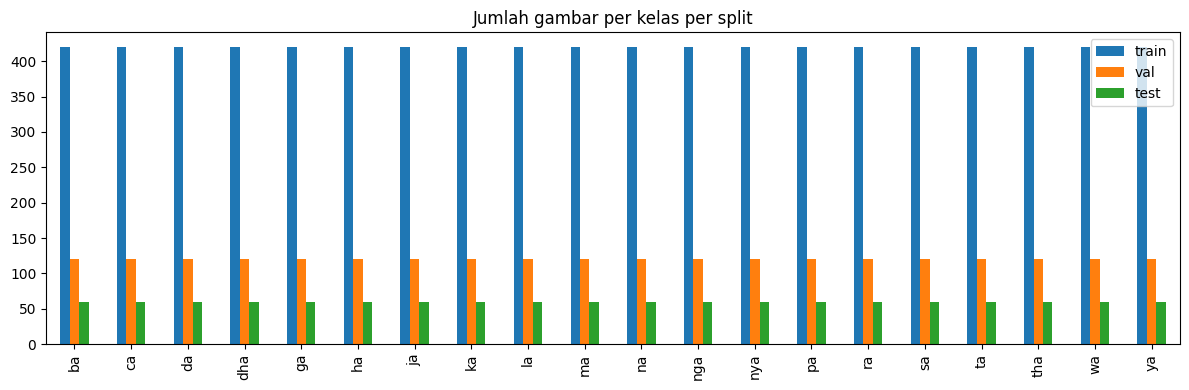

In [30]:
df_counts = pd.DataFrame({s: pd.Series(Y[s]).value_counts().sort_index().values for s in SPLITS}, index=class_names)
print(df_counts.sum())
df_counts.plot(kind="bar", figsize=(12, 4), title="Jumlah gambar per kelas per split")
plt.tight_layout(); plt.show()

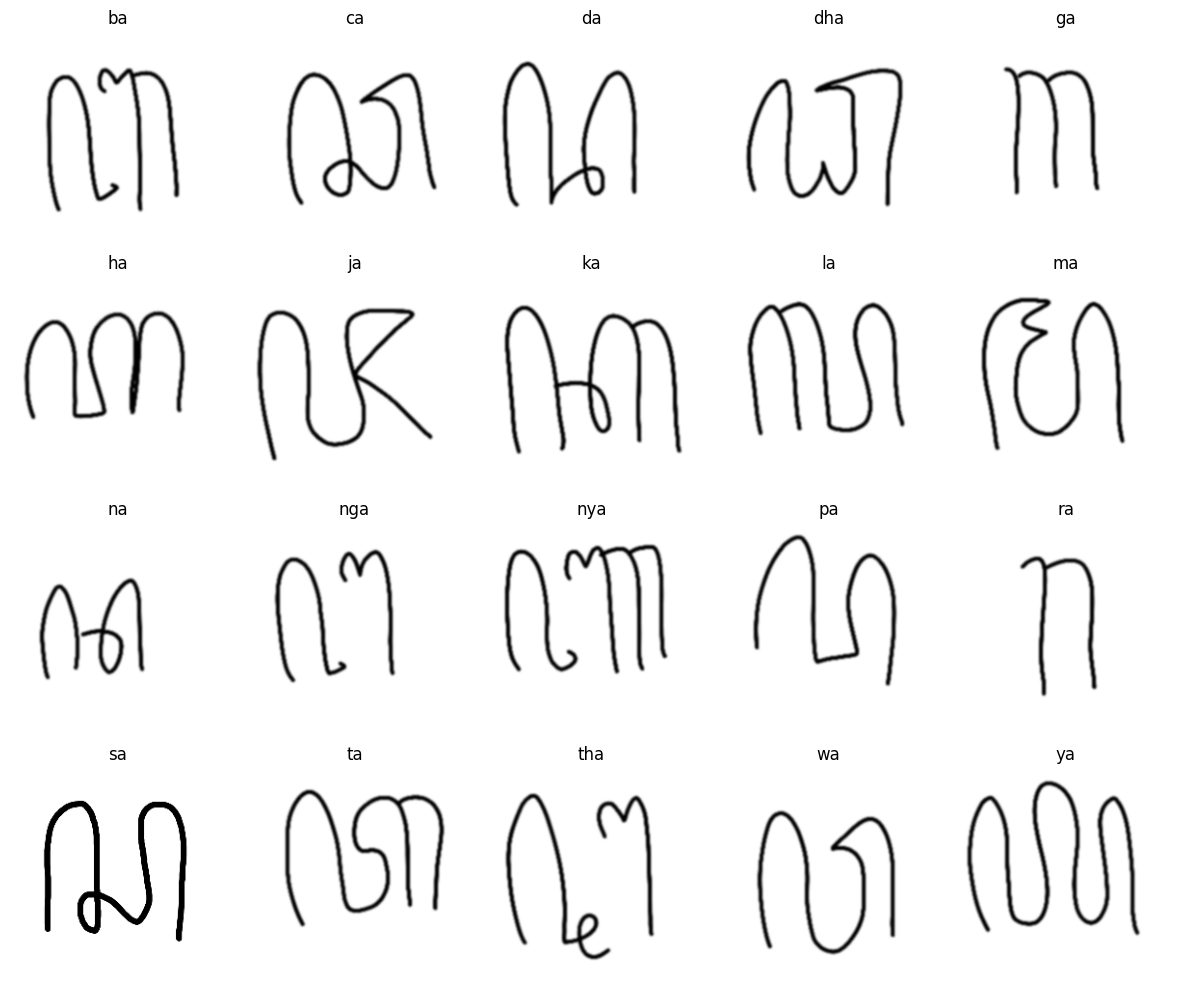

In [31]:
# Contoh gambar: 1 gambar per kelas
fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for ax, ci in zip(axes.ravel(), range(NUM_CLASSES)):
    p = P["train"][Y["train"] == ci][0]
    ax.imshow(keras.utils.load_img(p)); ax.set_title(class_names[ci]); ax.axis("off")
plt.tight_layout(); plt.show()

### Cek & bersihkan kebocoran data (data leakage)
Jika varian dari tulisan asli yang sama muncul di dua split, model bisa "mengenali tulisan yang sudah pernah dilihat" sehingga akurasi terlalu optimis. Gambar val yang tulisan aslinya juga ada di train atau test **dibuang dari val**. Test tidak diubah agar tetap sebanding dengan split bawaan dataset.

In [32]:
ov_tv = set(STEM["train"]) & set(STEM["val"])
ov_tt = set(STEM["train"]) & set(STEM["test"])
ov_vt = set(STEM["val"]) & set(STEM["test"])
print("overlap train & val :", sorted(ov_tv))
print("overlap train & test:", sorted(ov_tt))
print("overlap val & test  :", sorted(ov_vt))
assert not ov_tt, "Ada tulisan asli yang sama di train dan test - test tidak bisa dipercaya!"

drop = np.isin(STEM["val"], sorted(ov_tv | ov_vt))
n_val_before = len(P["val"])
P["val"], Y["val"], STEM["val"] = P["val"][~drop], Y["val"][~drop], STEM["val"][~drop]
print(f"\nVal dibersihkan: {drop.sum()} gambar dibuang -> val {len(P['val'])} gambar (sebelumnya {n_val_before}) "
      f"dari {len(set(STEM['val']))} tulisan asli")
vc = pd.Series(Y["val"]).value_counts()
print(f"Gambar val per kelas setelah dibersihkan: min {vc.min()}, maks {vc.max()}")

overlap train & val : [np.str_('da57'), np.str_('ka45'), np.str_('la69'), np.str_('ra44'), np.str_('sa67'), np.str_('ta6')]
overlap train & test: []
overlap val & test  : [np.str_('la9'), np.str_('ta85')]

Val dibersihkan: 161 gambar dibuang -> val 2239 gambar (sebelumnya 2400) dari 72 tulisan asli
Gambar val per kelas setelah dibersihkan: min 63, maks 120


In [33]:
# Pipeline data: baca gambar -> ubah ukuran -> (CPU: simpan di RAM agar epoch berikutnya cepat) -> batch
def _load(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)          # nilai piksel tetap 0-255 (dinormalisasi di dalam model)
    img.set_shape((*IMG_SIZE, 3))
    return img, label

def make_ds(paths, labels, shuffle=False, cache=CPU_MODE):
    paths, labels = np.asarray(paths), np.asarray(labels, dtype="int32")
    if shuffle:                                    # acak urutan file dulu (file tersusun per kelas)
        idx = np.random.default_rng(SEED).permutation(len(paths)); paths, labels = paths[idx], labels[idx]
    ds = tf.data.Dataset.from_tensor_slices((paths, labels)).map(_load, num_parallel_calls=AUTOTUNE)
    if cache: ds = ds.cache()
    if shuffle: ds = ds.shuffle(2000, seed=SEED)   # acak lagi setiap epoch
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(P["train"], Y["train"], shuffle=True)
val_ds   = make_ds(P["val"], Y["val"])
test_ds  = make_ds(P["test"], Y["test"])
print("Batch:", [(x.shape, y.shape) for x, y in train_ds.take(1)])

Batch: [(TensorShape([64, 96, 96, 3]), TensorShape([64]))]


## 3. Arsitektur (slide 5)
- **ann** (E0): ANN/MLP tanpa convolution (Flatten -> Dense 256 -> Dense 128 -> Softmax), pembanding seperti slide kuliah "Loss Comparison of CNN Model and ANN Model". Memakai lr 1e-4, karena dengan lr 1e-3 neuron ReLU-nya "mati" dan model hanya menebak acak.
- **ann_bn** (E0b): ANN yang sama + BatchNormalization setelah tiap Dense
- **lecture** (E1): arsitektur contoh di materi dosen: Conv(16,3x3) -> MaxPool(2x2) -> Conv(32,3x3) -> MaxPool(2x2) -> Flatten -> Dense(64) -> Softmax
- **improved** (E2): CNN 4 blok Conv-BatchNorm-ReLU-MaxPool + GlobalAveragePooling + Dropout
- **Transfer learning** (E6, E7): MobileNetV2 pretrained ImageNet; tahap 1 backbone dikunci (hanya kepala baru yang dilatih), tahap 2 fine-tune beberapa layer terakhir dengan lr 10x lebih kecil

Kaitan dengan materi: aktivasi **ReLU** di hidden layer (mengatasi vanishing gradient), **Softmax** di output, loss **cross-entropy** (`sparse_categorical_crossentropy`, setara `categorical_crossentropy` pada label one-hot).

Augmentasi online sengaja **tanpa flip** karena aksara Jawa yang dibalik berubah bentuk.

### Kamus layer (baca dulu sebelum lihat kodenya)

Bayangkan gambar aksara sebagai papan kotak-kotak kecil (piksel), tiap kotak berisi angka 0-255 (gelap sampai terang). Model memproses gambar itu lapisan demi lapisan (layer). Tiap layer punya tugas sendiri:

| Layer | Tugasnya | Analogi | Pengaturan penting |
|---|---|---|---|
| `Rescaling(1/255)` | Mengubah angka piksel dari 0-255 menjadi 0-1 | Menyamakan satuan agar model tidak kaget dengan angka besar | - |
| `Conv2D` (convolution) | Menggeser "kaca pembesar" kecil ke seluruh gambar untuk mencari pola (garis, lengkungan, sudut) | Orang yang memindai tulisan dengan lup mencari bentuk tertentu | `filters` = jumlah kaca pembesar (tiap filter mencari pola berbeda), `3x3` = ukuran kaca pembesar, `padding="same"` = diberi bingkai kosong supaya ukuran gambar tidak menyusut |
| `BatchNormalization` | Menyeimbangkan skala angka di tengah jaringan | Menyamakan "volume" tiap bagian supaya belajar lebih stabil dan cepat | - |
| `ReLU` (activation) | Angka negatif jadi 0, angka positif tetap | Saklar: hanya sinyal yang kuat diteruskan | - |
| `MaxPooling2D` | Dari tiap kotak 2x2 ambil nilai terbesar, ukuran gambar jadi setengah | Meringkas: simpan bagian yang paling menonjol, buang detail kecil | `(2,2)` = ukuran kotak ringkasan |
| `Flatten` | Meratakan hasil jadi satu deretan angka panjang | Membuka lipatan kertas menjadi satu garis | - |
| `GlobalAveragePooling2D` | Tiap peta pola diringkas jadi satu angka rata-rata | Versi Flatten yang jauh lebih hemat (parameter lebih sedikit, lebih tahan overfitting) | - |
| `Dense` (fully connected) | Menggabungkan semua temuan lalu memutuskan | Juri yang membaca semua laporan lalu memberi keputusan | jumlah neuron = "ukuran otak juri" |
| `Dropout` | Saat belajar, sebagian neuron dimatikan acak | Teman kelompok yang sengaja absen bergantian, jadi semua harus paham, tidak ada yang menghafal sendiri | `0.5` = 50% dimatikan |
| `Dense(20, softmax)` | Lapisan akhir: 20 neuron (1 per huruf), skor diubah jadi persentase | Papan hasil: ba 90%, da 6%, ha 4% ... | jumlah = jumlah kelas |

**Alur umum CNN:** Gambar -> [Conv -> ReLU -> Pooling] diulang beberapa kali -> Flatten/GlobalAvgPool -> Dense -> Softmax -> tebakan huruf.
Makin ke dalam, filter makin banyak (32, 64, 128, ...) dan gambar makin kecil: yang dipelajari berubah dari pola sederhana (garis) menjadi pola rumit (bentuk huruf).

In [34]:
# ---------- Augmentasi online (aktif hanya jika use_aug=True) ----------
# Setiap kali gambar dipakai belajar, diubah sedikit secara acak -> model tidak sekadar menghafal.
augment = keras.Sequential([
    layers.RandomRotation(0.05),            # putar acak sampai sekitar +-18 derajat
    layers.RandomTranslation(0.05, 0.05),   # geser acak maksimal 5% ke atas/bawah/kiri/kanan
    layers.RandomZoom(0.1),                 # perbesar/perkecil acak maksimal 10%
], name="augment")                          # (tidak ada flip: huruf yang dibalik berubah bentuk)


# ---------- Model dari nol: ANN, CNN materi dosen, CNN improved ----------
def build_cnn(kind="improved", dropout=0.5, use_aug=False):
    inp = keras.Input((*IMG_SIZE, 3))       # pintu masuk: gambar berwarna (tinggi x lebar x 3 kanal RGB)
    x = inp
    if use_aug: x = augment(x)              # (opsional) ubah gambar acak sedikit
    x = layers.Rescaling(1.0 / 255)(x)      # angka piksel 0-255 -> 0-1

    if kind == "ann":
        # ANN biasa: tidak ada convolution, gambar langsung "diratakan"
        x = layers.Resizing(64, 64)(x)                       # kecilkan ke 64x64 agar jumlah input tidak terlalu besar
        x = layers.Flatten()(x)                              # ratakan 64*64*3 = 12.288 angka jadi satu deretan
        x = layers.Dense(256, activation="relu")(x)          # 256 neuron: gabungkan semua angka piksel
        x = layers.Dense(128, activation="relu")(x)          # 128 neuron: peringkas lagi
        x = layers.Dropout(dropout)(x)                       # matikan sebagian neuron acak saat belajar

    elif kind == "ann_bn":
        # ANN yang sama + BatchNorm: skala angka di tiap layer diseimbangkan agar ReLU tidak "mati"
        x = layers.Resizing(64, 64)(x)
        x = layers.Flatten()(x)
        for units in (256, 128):
            x = layers.Dense(units, use_bias=False)(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation("relu")(x)
        x = layers.Dropout(dropout)(x)

    elif kind == "lecture":
        # CNN persis seperti contoh di slide dosen
        x = layers.Conv2D(16, (3, 3), activation="relu", padding="same")(x)  # 16 kaca pembesar 3x3 -> 16 peta pola (ukuran tetap 224x224)
        x = layers.MaxPooling2D((2, 2))(x)                   # ringkas 2x2 -> ukuran jadi 112x112
        x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(x)  # 32 kaca pembesar: pola lebih rumit dari pola tahap 1
        x = layers.MaxPooling2D((2, 2))(x)                   # ringkas lagi -> 56x56 (isi: 32 peta pola)
        x = layers.Flatten()(x)                              # ratakan 56*56*32 = 100.352 angka jadi satu deretan
        x = layers.Dense(64, activation="relu")(x)           # 64 neuron: gabungkan semua temuan
        x = layers.Dropout(dropout)(x)                       # (di E1 nilainya 0 = tidak dipakai, sesuai materi)

    else:
        # CNN improved: lebih dalam, ditambah BatchNorm dan GlobalAveragePooling
        for f in [32, 64, 128, 256]:                         # 4 blok; filter makin banyak, gambar makin kecil
            x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)  # f kaca pembesar 3x3 (bias tak perlu karena ada BatchNorm)
            x = layers.BatchNormalization()(x)               # seimbangkan skala angka agar belajar stabil
            x = layers.Activation("relu")(x)                 # saklar ReLU: negatif -> 0
            x = layers.MaxPooling2D()(x)                     # ringkas 2x2: 224 -> 112 -> 56 -> 28 -> 14
        x = layers.GlobalAveragePooling2D()(x)               # tiap 256 peta pola diringkas jadi 1 angka -> 256 angka
        x = layers.Dense(128, activation="relu")(x)          # 128 neuron: gabungkan temuan
        x = layers.Dropout(dropout)(x)                       # cegah menghafal

    out = layers.Dense(NUM_CLASSES, activation="softmax")(x) # 20 neuron (1 per huruf); softmax -> persentase tiap huruf
    return keras.Model(inp, out, name=f"cnn_{kind}"), None


# ---------- Transfer learning: pakai model yang sudah pintar (pretrained ImageNet) ----------
BACKBONES = {
    "mobilenetv2":    (keras.applications.MobileNetV2,    keras.applications.mobilenet_v2.preprocess_input),
    "resnet50":       (keras.applications.ResNet50,       keras.applications.resnet50.preprocess_input),
    "efficientnetb0": (keras.applications.EfficientNetB0, keras.applications.efficientnet.preprocess_input),
}

def build_transfer(name, dropout=0.3, use_aug=False):
    base_fn, prep = BACKBONES[name]
    # "backbone" = bagian pengenal pola dari model pretrained (tanpa lapisan tebakan akhirnya, include_top=False)
    base = base_fn(include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
    base.trainable = False                                   # kunci dulu: pengetahuan lamanya tidak diubah
    inp = keras.Input((*IMG_SIZE, 3)); x = inp               # pintu masuk gambar
    if use_aug: x = augment(x)                               # (opsional) augmentasi
    x = layers.Lambda(prep, name="preprocess")(x)            # siapkan gambar sesuai "selera" model pretrained
    x = base(x, training=False)                              # backbone mencari pola; training=False menjaga BatchNorm-nya tetap
    x = layers.GlobalAveragePooling2D()(x)                   # ringkas peta pola jadi satu deretan angka
    x = layers.Dropout(dropout)(x)                           # cegah menghafal
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x) # kepala baru: 20 huruf aksara Jawa (inilah yang dilatih lebih dulu)
    return keras.Model(inp, out, name=name), base

SCRATCH_ARCHS = ("ann", "ann_bn", "lecture", "improved")   # model yang dilatih dari nol

def build_from_cfg(cfg):
    if cfg["arch"] in SCRATCH_ARCHS:
        return build_cnn(cfg["arch"], cfg["dropout"], cfg["aug"])
    return build_transfer(cfg["arch"], cfg["dropout"], cfg["aug"])

# Coba buat satu model dan lihat susunannya
m, _ = build_from_cfg({"arch": "lecture", "dropout": 0.0, "aug": False})
m.summary()   # tabel: nama layer | bentuk keluaran | jumlah parameter (jumlah "tombol" yang dilatih)
# Cara baca: (None, 112, 112, 16) = (jumlah gambar per batch, tinggi, lebar, jumlah peta pola)
# Coba ganti "lecture" jadi "ann" / "improved" dan bandingkan jumlah parameternya.

Model: "cnn_lecture"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 96, 96, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 48, 48, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 48, 48, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │     1,179,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 20)             │         1,300 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,186,100 (4.52 MB)

 Trainable params: 1,186,100 (4.52 MB)

 Non-trainable params: 0 (0.00 B)

In [35]:
# Ringkasan arsitektur untuk slide 5: jumlah parameter & susunan layer tiap model
rows = []
for nama, cfg in [("ANN (E0)", dict(arch="ann", dropout=0.3)), ("ANN + BatchNorm (E0b)", dict(arch="ann_bn", dropout=0.3)),
                  ("CNN materi (E1)", dict(arch="lecture", dropout=0.0)), ("CNN improved (E2)", dict(arch="improved", dropout=0.5)),
                  ("MobileNetV2 (E6/E7)", dict(arch="mobilenetv2", dropout=0.3))]:
    m, _ = build_from_cfg({"aug": False, **cfg})
    utama = [l.__class__.__name__ for l in m.layers if l.__class__.__name__ not in ("InputLayer", "Rescaling", "Resizing")]
    rows.append(dict(model=nama, total_params=m.count_params(),
                     trainable_params=int(sum(np.prod(w.shape) for w in m.trainable_weights)), susunan=" -> ".join(utama)))
arch_df = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", None)
display(arch_df)
keras.backend.clear_session()
m, _ = build_from_cfg({"arch": "improved", "dropout": 0.5, "aug": False}); m.summary()   # detail model final

,model,total_params,trainable_params,susunan
0,ANN (E0),3181460,3181460,Flatten -> Dense -> Dense -> Dropout -> Dense
1,ANN + BatchNorm (E0b),3182612,3181844,Flatten -> Dense -> BatchNormalization -> Activation -> Dense -> BatchNormalization -> Activation -> Dropout -> Dense
2,CNN materi (E1),1186100,1186100,Conv2D -> MaxPooling2D -> Conv2D -> MaxPooling2D -> Flatten -> Dense -> Dropout -> Dense
3,CNN improved (E2),425332,424372,Conv2D -> BatchNormalization -> Activation -> MaxPooling2D -> Conv2D -> BatchNormalization -> Activation -> MaxPooling2D -> Conv2D -> BatchNormalization -> Activation -> MaxPooling2D -> Conv2D -> BatchNormalization -> Activation -> MaxPooling2D -> GlobalAveragePooling2D -> Dense -> Dropout -> Dense
4,MobileNetV2 (E6/E7),2283604,25620,Lambda -> Functional -> GlobalAveragePooling2D -> Dropout -> Dense


Model: "cnn_improved"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 96, 96, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 96, 96, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 425,332 (1.62 MB)

 Trainable params: 424,372 (1.62 MB)

 Non-trainable params: 960 (3.75 KB)

## 4. Strategi Training & Eksperimen (slide 6)
- **Optimizer** Adam (atau SGD+momentum 0.9), loss cross-entropy, metrik akurasi
- **EarlyStopping** (patience 5, kembalikan bobot terbaik) dan **ReduceLROnPlateau** (lr x0.3 jika val_loss macet 2 epoch)
- **Fine-tuning** transfer learning: lr dibagi 10, BatchNorm backbone tetap dibekukan; jika fine-tuning malah memperburuk val_loss, bobot tahap 1 dipakai
- **3 fase eksperimen:**
  1. *Screening* arsitektur (ANN, CNN materi, CNN improved, MobileNetV2 frozen & fine-tune)
  2. *Random search* hyperparameter (lr, optimizer, dropout, augmentasi, jumlah layer di-unfreeze) pada 2 arsitektur terbaik, tanpa konfigurasi kembar
  3. *Uji kestabilan*: konfigurasi terbaik tiap arsitektur dilatih ulang dengan 3 seed -> rata-rata ± simpangan baku; model final = rata-rata validasi tertinggi

In [36]:
DEFAULT = dict(lr=1e-3, optimizer="adam", dropout=0.3, aug=False, epochs=30, epochs_head=5, epochs_ft=15,
               finetune=False, unfreeze_last=30, seed=SEED, phase=1)

def compile_model(model, lr, optimizer):
    opt = keras.optimizers.Adam(lr) if optimizer == "adam" else keras.optimizers.SGD(lr, momentum=0.9)
    model.compile(opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])

def get_callbacks():
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6)]

def merge_hist(*hs):
    out = {}
    for h in hs:
        for k, v in h.items(): out.setdefault(k, []).extend(v)
    return out

def train_model(cfg, tr, va, verbose=2):
    keras.backend.clear_session()
    tf.random.set_seed(cfg["seed"]); np.random.seed(cfg["seed"]); random.seed(cfg["seed"])
    model, base = build_from_cfg(cfg)
    compile_model(model, cfg["lr"], cfg["optimizer"])
    if base is None:                                     # model dari nol: satu tahap
        h = model.fit(tr, validation_data=va, epochs=cfg["epochs"], callbacks=get_callbacks(), verbose=verbose)
        return model, h.history
    # Transfer learning tahap 1: backbone dikunci, hanya kepala baru yang belajar
    h1 = model.fit(tr, validation_data=va, epochs=cfg["epochs_head"], callbacks=get_callbacks(), verbose=verbose)
    if not cfg["finetune"]:
        return model, h1.history
    best_v1 = min(h1.history["val_loss"])
    tmp_w = os.path.join(tempfile.gettempdir(), "aksara_phase1.weights.h5")
    model.save_weights(tmp_w)                            # cadangan hasil tahap 1
    # Tahap 2 (fine-tune): buka beberapa layer terakhir backbone, lr 10x lebih kecil, BatchNorm tetap beku
    base.trainable = True
    for l in base.layers[:-cfg["unfreeze_last"]]: l.trainable = False
    for l in base.layers:
        if isinstance(l, layers.BatchNormalization): l.trainable = False
    compile_model(model, cfg["lr"] / 10, cfg["optimizer"])
    h2 = model.fit(tr, validation_data=va, epochs=cfg["epochs_ft"], callbacks=get_callbacks(), verbose=verbose)
    if min(h2.history["val_loss"]) > best_v1:            # pengaman: fine-tune malah merusak -> pakai tahap 1
        print(f"  Fine-tune tidak membaik (val_loss {min(h2.history['val_loss']):.4f} > {best_v1:.4f}) -> pakai bobot tahap 1")
        model.load_weights(tmp_w)
    hist = merge_hist(h1.history, h2.history)
    hist["phase1_epochs"] = [len(h1.history["loss"])]
    return model, hist

def predict_ds(model, ds):
    y_true = np.concatenate([y.numpy() for _, y in ds])
    y_pred = model.predict(ds, verbose=0).argmax(1)
    return y_true, y_pred

def cfg_key(cfg):
    # identitas konfigurasi (tanpa nama & seed) -> untuk mencegah konfigurasi kembar
    cfg = {**DEFAULT, **cfg}
    return (cfg["arch"], float(cfg["lr"]), cfg["optimizer"], float(cfg["dropout"]), bool(cfg["aug"]),
            bool(cfg["finetune"]), int(cfg["unfreeze_last"]) if cfg["finetune"] else None)

In [37]:
# ---------------- Fase 1: screening arsitektur ----------------
experiments = [
    dict(name="E0_ann",                     arch="ann",            dropout=0.3, epochs=30, lr=1e-4),
    dict(name="E0b_ann_bn",                 arch="ann_bn",         dropout=0.3, epochs=30),
    dict(name="E1_cnn_lecture",             arch="lecture",        dropout=0.0, epochs=30),
    dict(name="E2_improved_cnn",            arch="improved",       dropout=0.5, epochs=40),
    dict(name="E3_improved_cnn_aug",        arch="improved",       dropout=0.5, epochs=40, aug=True),
    dict(name="E6_mobilenetv2_frozen",      arch="mobilenetv2",    epochs_head=10),
    dict(name="E7_mobilenetv2_finetune",    arch="mobilenetv2",    finetune=True),
    dict(name="E8_resnet50_finetune",       arch="resnet50",       finetune=True),
    dict(name="E9_efficientnetb0_finetune", arch="efficientnetb0", finetune=True),
]
if CPU_MODE:   # subset + epoch dibatasi agar selesai dalam waktu wajar di CPU
    keep = {"E0_ann", "E0b_ann_bn", "E1_cnn_lecture", "E2_improved_cnn", "E6_mobilenetv2_frozen", "E7_mobilenetv2_finetune"}
    experiments = [e for e in experiments if e["name"] in keep]
    DEFAULT.update(epochs_ft=5)
    for e in experiments:
        cap = 30 if e["arch"] in ("ann", "ann_bn") else 15       # ANN murah, boleh lebih lama
        e["epochs"] = min(e.get("epochs", DEFAULT["epochs"]), cap)
        e["epochs_head"] = min(e.get("epochs_head", DEFAULT["epochs_head"]), 6)
print("Eksperimen fase 1:", [e["name"] for e in experiments])

# Penyimpanan hasil (tidak hilang saat kernel di-restart)
OUT_DIR = os.path.join(SRC, "output_final")
MODEL_DIR = os.path.join(OUT_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)
RESULTS_CSV = os.path.join(OUT_DIR, "results.csv")
STATE_JSON = os.path.join(OUT_DIR, "state.json")
results = pd.read_csv(RESULTS_CSV).to_dict("records") if os.path.exists(RESULTS_CSV) else []
if results and "phase" not in results[0]:
    raise RuntimeError(f"{RESULTS_CSV} berisi hasil dari notebook versi lama. Pindahkan/ganti nama folder {OUT_DIR} dulu, lalu Run All lagi.")
state = json.load(open(STATE_JSON)) if os.path.exists(STATE_JSON) else {"cfgs": {}, "hists": {}}
all_cfgs, hists = state["cfgs"], state["hists"]
base_cfgs = {e["name"]: {**DEFAULT, **e} for e in experiments}
print("Folder output:", OUT_DIR, "| eksperimen yang sudah tersimpan:", len(results))

def run_experiment(c):
    cfg = {**DEFAULT, **c}
    if cfg["name"] in {r["name"] for r in results}:
        print("Lewati (sudah selesai):", cfg["name"]); return
    print(f"\n===== {cfg['name']} =====")
    t0 = time.time()
    model, hist = train_model(cfg, train_ds, val_ds)
    elapsed = time.time() - t0
    yv, pv = predict_ds(model, val_ds)
    yt, pt = predict_ds(model, test_ds)
    row = dict(name=cfg["name"], phase=cfg["phase"], arch=cfg["arch"], lr=cfg["lr"], optimizer=cfg["optimizer"],
               dropout=cfg["dropout"], aug=cfg["aug"], finetune=cfg["finetune"],
               unfreeze_last=cfg["unfreeze_last"] if cfg["finetune"] else None, seed=cfg["seed"],
               params=model.count_params(), train_acc=max(hist["accuracy"]), val_acc=float((yv == pv).mean()),
               test_acc=float((yt == pt).mean()), test_f1_macro=f1_score(yt, pt, average="macro"),
               epochs_run=len(hist["loss"]), time_s=round(elapsed))
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in row.items()})
    model.save_weights(os.path.join(MODEL_DIR, f"{cfg['name']}.weights.h5"))
    if cfg["arch"] in SCRATCH_ARCHS:      # model dari nol disimpan penuh (seperti model.save di materi)
        model.save(os.path.join(MODEL_DIR, f"{cfg['name']}.keras"))
    results.append(row); pd.DataFrame(results).to_csv(RESULTS_CSV, index=False)
    hists[cfg["name"]] = {k: [float(v) for v in vs] for k, vs in hist.items()}
    all_cfgs[cfg["name"]] = cfg
    json.dump({"cfgs": all_cfgs, "hists": hists}, open(STATE_JSON, "w"))

def load_trained(name):
    # bangun ulang model dari konfigurasi + bobot yang tersimpan (tanpa training ulang)
    keras.backend.clear_session()
    model, _ = build_from_cfg(all_cfgs[name])
    model.load_weights(os.path.join(MODEL_DIR, f"{name}.weights.h5"))
    return model

for c in experiments:
    run_experiment(c)

Eksperimen fase 1: ['E0_ann', 'E0b_ann_bn', 'E1_cnn_lecture', 'E2_improved_cnn', 'E6_mobilenetv2_frozen', 'E7_mobilenetv2_finetune']
Folder output: D:\aksara_jawa\output_final | eksperimen yang sudah tersimpan: 20
Lewati (sudah selesai): E0_ann
Lewati (sudah selesai): E0b_ann_bn
Lewati (sudah selesai): E1_cnn_lecture
Lewati (sudah selesai): E2_improved_cnn
Lewati (sudah selesai): E6_mobilenetv2_frozen
Lewati (sudah selesai): E7_mobilenetv2_finetune


### Fase 2 - Random search hyperparameter
Didalami 2 **arsitektur** terbaik dari fase 1 (berdasarkan validasi). Ruang pencarian: optimizer (Adam/SGD), learning rate (rentang disesuaikan per optimizer, karena SGD butuh lr lebih besar dari Adam), dropout, augmentasi, dan jumlah layer yang di-unfreeze (transfer learning). Konfigurasi yang sama tidak diambil dua kali.

In [38]:
N_TRIALS = 4 if CPU_MODE else 6      # per arsitektur
TOP_K = 2                            # jumlah arsitektur yang didalami
LR_SPACE = {"adam": [3e-3, 1e-3, 3e-4, 1e-4], "sgd": [3e-2, 1e-2, 3e-3]}
DROPOUT_SPACE, AUG_SPACE, UNFREEZE_SPACE = [0.2, 0.3, 0.5], [False, True], [20, 30, 60]

def top_bases(k=TOP_K):
    df = pd.DataFrame(results); df = df[df["phase"] == 1].sort_values("val_acc", ascending=False)
    picked, archs = [], set()
    for _, r in df.iterrows():                      # satu perwakilan per arsitektur
        if r["arch"] not in archs:
            picked.append(r["name"]); archs.add(r["arch"])
        if len(picked) == k: break
    return picked

def random_search(base_name, n_trials=N_TRIALS):
    rng = random.Random(f"{SEED}-{base_name}")      # urutan acak tetap -> bisa dilanjutkan jika terputus
    base = base_cfgs[base_name]
    seen = {cfg_key(base)}
    for t in range(1, n_trials + 1):
        for _ in range(500):
            opt = rng.choice(["adam", "sgd"])
            trial = dict(optimizer=opt, lr=rng.choice(LR_SPACE[opt]), dropout=rng.choice(DROPOUT_SPACE), aug=rng.choice(AUG_SPACE))
            if base["finetune"]: trial["unfreeze_last"] = rng.choice(UNFREEZE_SPACE)
            cfg = {**base, **trial, "name": f"R_{base_name}_t{t}", "phase": 2}
            if cfg_key(cfg) not in seen: break
        seen.add(cfg_key(cfg))
        print("Trial", t, trial)
        run_experiment(cfg)

BASES = top_bases()
print("Arsitektur yang didalami:", BASES)
for b in BASES:
    print("\n##### Random search:", b)
    random_search(b)

Arsitektur yang didalami: ['E2_improved_cnn', 'E7_mobilenetv2_finetune']

##### Random search: E2_improved_cnn
Trial 1 {'optimizer': 'adam', 'lr': 0.003, 'dropout': 0.2, 'aug': True}
Lewati (sudah selesai): R_E2_improved_cnn_t1
Trial 2 {'optimizer': 'adam', 'lr': 0.0003, 'dropout': 0.5, 'aug': False}
Lewati (sudah selesai): R_E2_improved_cnn_t2
Trial 3 {'optimizer': 'sgd', 'lr': 0.03, 'dropout': 0.2, 'aug': False}
Lewati (sudah selesai): R_E2_improved_cnn_t3
Trial 4 {'optimizer': 'sgd', 'lr': 0.003, 'dropout': 0.2, 'aug': True}
Lewati (sudah selesai): R_E2_improved_cnn_t4

##### Random search: E7_mobilenetv2_finetune
Trial 1 {'optimizer': 'adam', 'lr': 0.0001, 'dropout': 0.2, 'aug': True, 'unfreeze_last': 60}
Lewati (sudah selesai): R_E7_mobilenetv2_finetune_t1
Trial 2 {'optimizer': 'adam', 'lr': 0.0001, 'dropout': 0.5, 'aug': False, 'unfreeze_last': 60}
Lewati (sudah selesai): R_E7_mobilenetv2_finetune_t2
Trial 3 {'optimizer': 'sgd', 'lr': 0.003, 'dropout': 0.5, 'aug': True, 'unfreeze

### Fase 3 - Uji kestabilan dengan 3 seed
Satu kali training bisa kebetulan bagus atau jelek. Konfigurasi terbaik dari **setiap** arsitektur yang didalami dilatih ulang dengan 3 seed baru. Yang dilaporkan adalah rata-rata ± simpangan baku dari run seed ini saja (run awal tidak ikut dirata-rata karena terpilih justru karena nilainya tinggi). Jika selisih dua model lebih kecil dari simpangan bakunya, keduanya dianggap setara.

In [39]:
SEEDS = (1, 2, 3)
df_r = pd.DataFrame(results)
cand = df_r[df_r["phase"].isin([1, 2])].sort_values("val_acc", ascending=False)
top_archs = [base_cfgs[b]["arch"] for b in BASES]
finalists = [cand[cand["arch"] == a].iloc[0]["name"] for a in top_archs]
print("Finalis:", finalists)
for name in finalists:
    for sd in SEEDS:
        run_experiment({**all_cfgs[name], "seed": sd, "name": f"S_{name}_seed{sd}", "phase": 3})

df_s = pd.DataFrame(results)
df_s = df_s[df_s["phase"] == 3].copy()
df_s["config"] = df_s["name"].str.replace(r"_seed\d+$", "", regex=True).str[2:]
summary = (df_s.groupby("config")
           .agg(arch=("arch", "first"), params=("params", "first"), n_run=("val_acc", "size"),
                val_mean=("val_acc", "mean"), val_std=("val_acc", "std"),
                test_mean=("test_acc", "mean"), test_std=("test_acc", "std"),
                f1_mean=("test_f1_macro", "mean"), f1_std=("test_f1_macro", "std"))
           .sort_values("val_mean", ascending=False).round(4))
display(summary)
summary.to_csv(os.path.join(OUT_DIR, "seed_summary.csv"))

FINAL_CONFIG = summary.index[0]                                     # rata-rata validasi tertinggi
FINAL_NAME = df_s[df_s["config"] == FINAL_CONFIG].sort_values("val_acc", ascending=False).iloc[0]["name"]
print("Konfigurasi final:", FINAL_CONFIG, "| run yang dianalisis (val tertinggi):", FINAL_NAME)

Finalis: ['E2_improved_cnn', 'E7_mobilenetv2_finetune']
Lewati (sudah selesai): S_E2_improved_cnn_seed1
Lewati (sudah selesai): S_E2_improved_cnn_seed2
Lewati (sudah selesai): S_E2_improved_cnn_seed3
Lewati (sudah selesai): S_E7_mobilenetv2_finetune_seed1
Lewati (sudah selesai): S_E7_mobilenetv2_finetune_seed2
Lewati (sudah selesai): S_E7_mobilenetv2_finetune_seed3


,arch,params,n_run,val_mean,val_std,test_mean,test_std,f1_mean,f1_std
config,,,,,,,,,
E2_improved_cnn,improved,425332,3,0.9792,0.0013,0.9594,0.0171,0.9585,0.0178
E7_mobilenetv2_finetune,mobilenetv2,2283604,3,0.9382,0.0003,0.9300,0.0254,0.9289,0.0256


Konfigurasi final: E2_improved_cnn | run yang dianalisis (val tertinggi): S_E2_improved_cnn_seed1


## 5. Hasil & Analisis (slide 7-9)

Grafik akurasi antararsitektur dikelompokkan menurut keluarga model. Kurva *loss* dan *accuracy* ditampilkan **satu grafik per metrik per model** supaya tidak bertumpuk. Nilai test dipakai untuk pelaporan, bukan untuk memilih konfigurasi model.


,name,phase,arch,lr,optimizer,dropout,aug,unfreeze_last,seed,params,train_acc,val_acc,test_acc,test_f1_macro,time_s
0,E2_improved_cnn,1,improved,0.0010,adam,0.5,False,NaN,42,425332,0.9902,0.9857,0.9575,0.9559,2775
1,E7_mobilenetv2_finetune,1,mobilenetv2,0.0010,adam,0.3,False,30.0,42,2283604,0.9923,0.9196,0.9350,0.9341,1792
2,E6_mobilenetv2_frozen,1,mobilenetv2,0.0010,adam,0.3,False,NaN,42,2283604,0.9292,0.8767,0.8808,0.8798,1089
3,E1_cnn_lecture,1,lecture,0.0010,adam,0.0,False,NaN,42,1186100,1.0000,0.5762,0.5800,0.5638,103
4,E0b_ann_bn,1,ann_bn,0.0010,adam,0.3,False,NaN,42,3182612,1.0000,0.5520,0.5983,0.5808,202
5,E0_ann,1,ann,0.0001,adam,0.3,False,NaN,42,3181460,0.5587,0.3953,0.4058,0.3919,193
6,R_E2_improved_cnn_t1,2,improved,0.0030,adam,0.2,True,NaN,42,425332,0.9802,0.9678,0.9583,0.9566,2708
7,R_E2_improved_cnn_t2,2,improved,0.0003,adam,0.5,False,NaN,42,425332,0.9840,0.9665,0.9783,0.9785,2619
8,R_E2_improved_cnn_t4,2,improved,0.0030,sgd,0.2,True,NaN,42,425332,0.9239,0.9634,0.9400,0.9392,2622
9,R_E7_mobilenetv2_finetune_t2,2,mobilenetv2,0.0001,adam,0.5,False,60.0,42,2283604,0.9526,0.9147,0.9125,0.9132,1937


Total waktu training: 16.1 jam


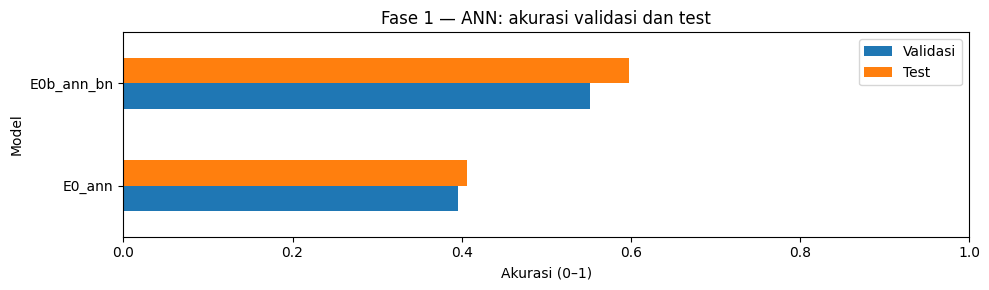

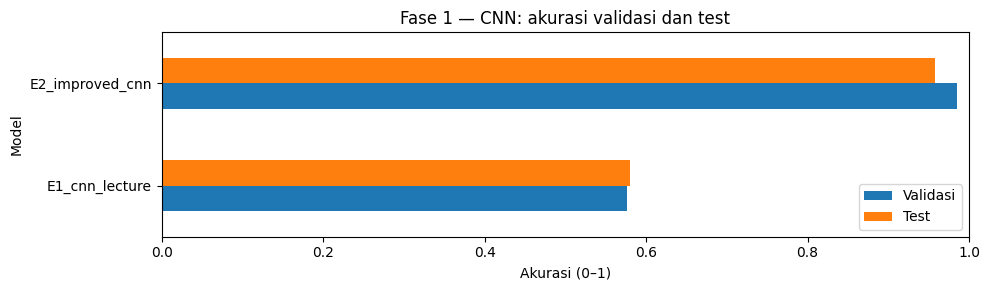

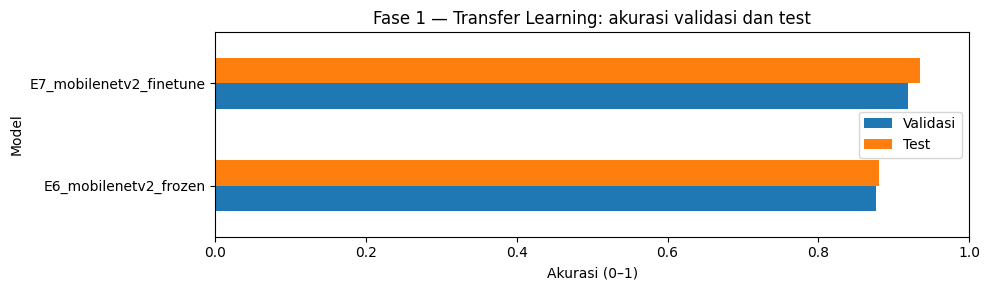

In [40]:
res = pd.DataFrame(results).sort_values(["phase", "val_acc"], ascending=[True, False]).reset_index(drop=True)
display(res[["name", "phase", "arch", "lr", "optimizer", "dropout", "aug", "unfreeze_last", "seed", "params",
             "train_acc", "val_acc", "test_acc", "test_f1_macro", "time_s"]].round(4))
print(f"Total waktu training: {res['time_s'].sum() / 3600:.1f} jam")

# Pisahkan grafik fase 1 menurut keluarga arsitektur.
def keluarga_model(arch):
    a = str(arch).lower()
    if a.startswith("ann"): return "ANN"
    if a in ("lecture", "improved") or "cnn" in a: return "CNN"
    return "Transfer Learning"

r1 = res[res["phase"] == 1].copy()
r1["keluarga"] = r1["arch"].map(keluarga_model)
for keluarga in ["ANN", "CNN", "Transfer Learning"]:
    subset = r1[r1["keluarga"] == keluarga].sort_values("val_acc")
    if subset.empty: continue
    ax = subset.set_index("name")[["val_acc", "test_acc"]].plot(kind="barh", figsize=(10, max(3, len(subset)*0.65+1)), xlim=(0, 1))
    ax.set_title(f"Fase 1 — {keluarga}: akurasi validasi dan test")
    ax.set_xlabel("Akurasi (0–1)"); ax.set_ylabel("Model")
    ax.legend(["Validasi", "Test"])
    plt.tight_layout(); plt.show()



=== GRAFIK ANN ===


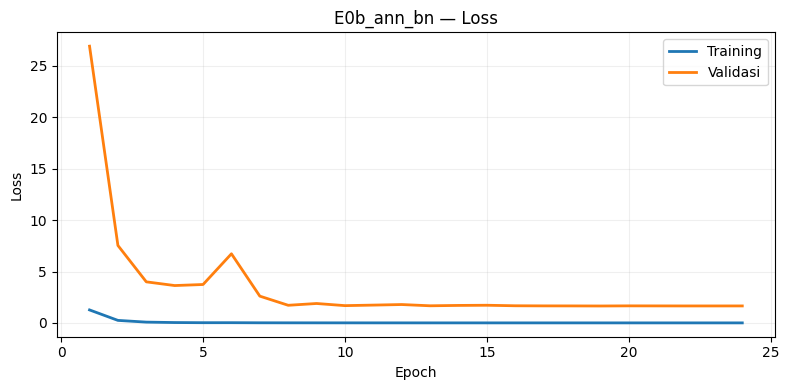

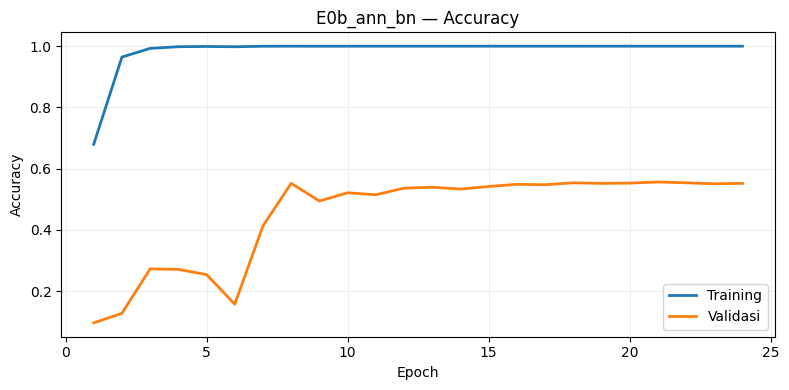

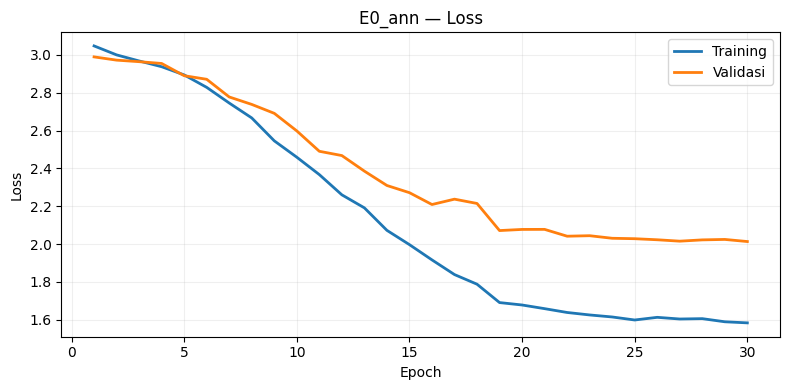

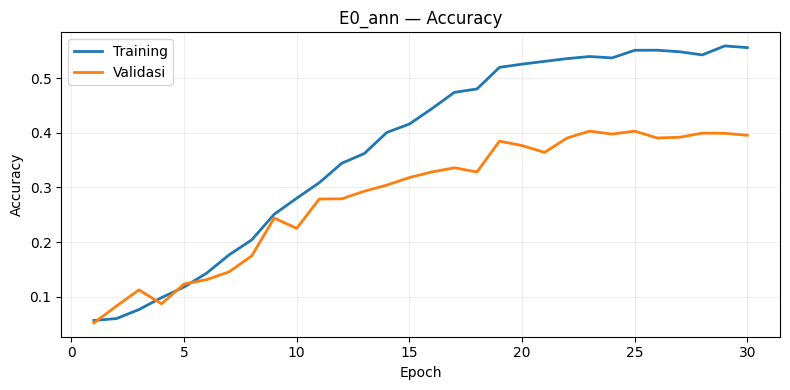


=== GRAFIK CNN ===


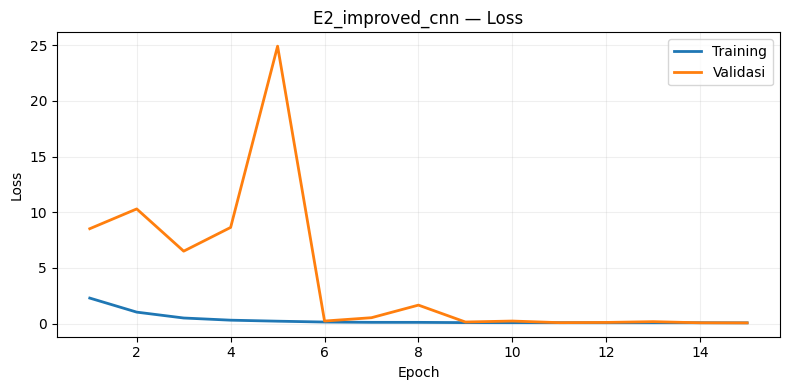

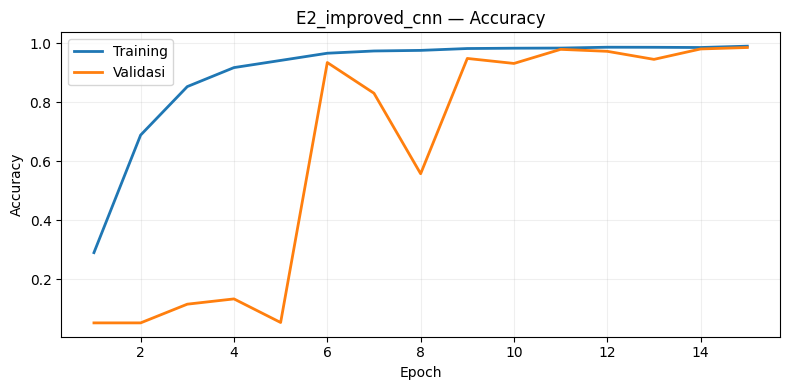

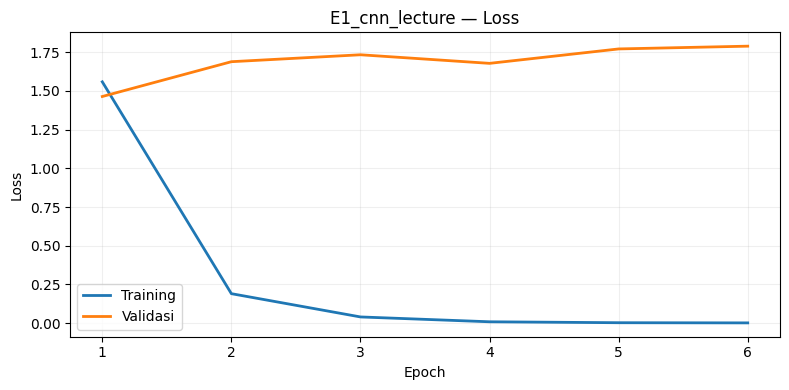

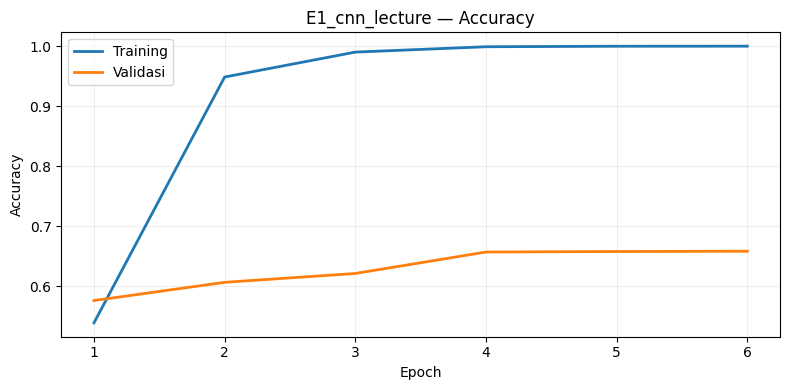


=== GRAFIK TRANSFER LEARNING ===


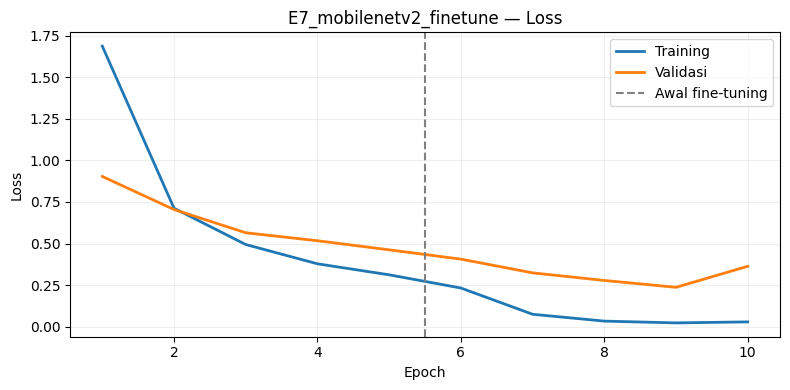

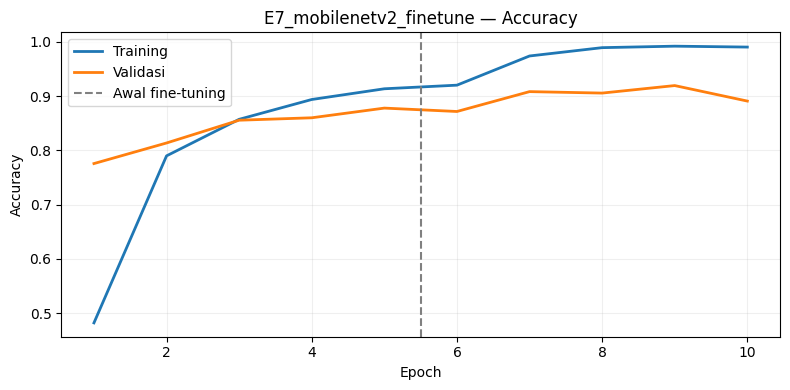

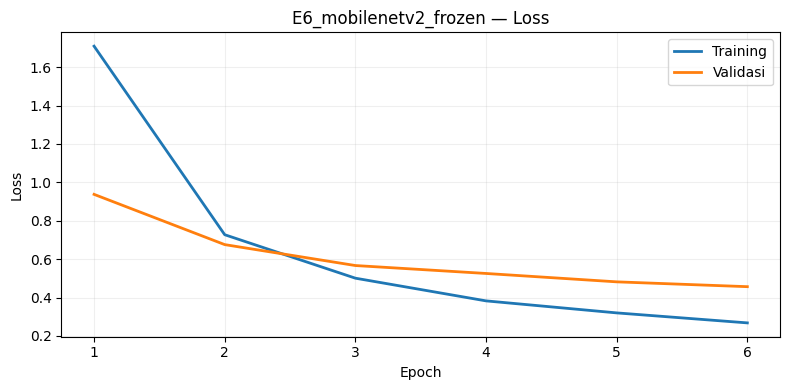

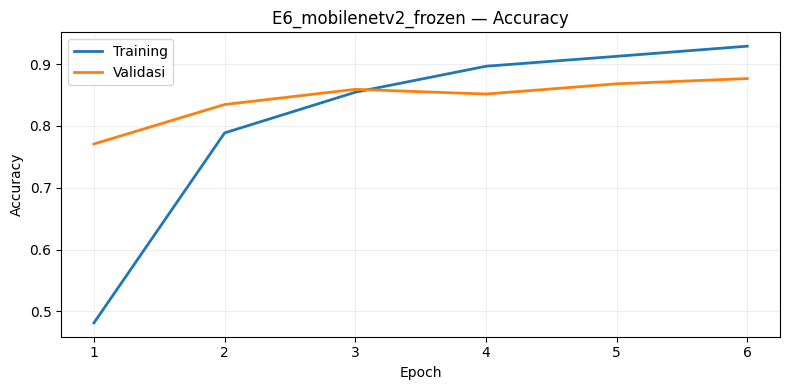

In [41]:
# Kurva belajar dipisah PER MODEL agar tidak saling bertumpuk.
def tampilkan_kurva_model(name, history):
    if not isinstance(history, dict) or "loss" not in history: return
    for metric, judul in [("loss", "Loss"), ("accuracy", "Accuracy")]:
        val_key = "val_" + metric
        if metric not in history: continue
        plt.figure(figsize=(8, 4))
        epochs = np.arange(1, len(history[metric]) + 1)
        plt.plot(epochs, history[metric], label="Training", linewidth=2)
        if val_key in history:
            plt.plot(np.arange(1, len(history[val_key])+1), history[val_key], label="Validasi", linewidth=2)
        if "phase1_epochs" in history:
            batas = history["phase1_epochs"][0]
            plt.axvline(batas + 0.5, linestyle="--", color="gray", label="Awal fine-tuning")
        plt.title(f"{name} — {judul}")
        plt.xlabel("Epoch"); plt.ylabel(judul)
        plt.grid(alpha=0.2); plt.legend(); plt.tight_layout(); plt.show()

for keluarga in ["ANN", "CNN", "Transfer Learning"]:
    nama_model = r1.loc[r1["keluarga"] == keluarga, "name"].tolist()
    if not nama_model: continue
    print(f"\n=== GRAFIK {keluarga.upper()} ===")
    for name in nama_model:
        if name in hists: tampilkan_kurva_model(name, hists[name])


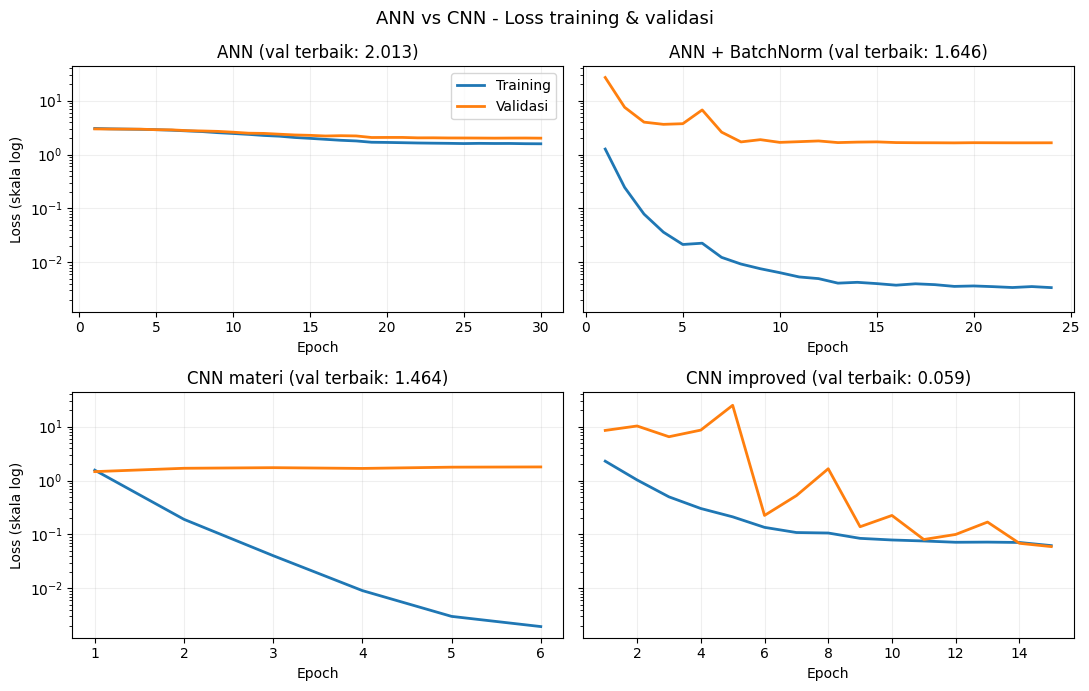

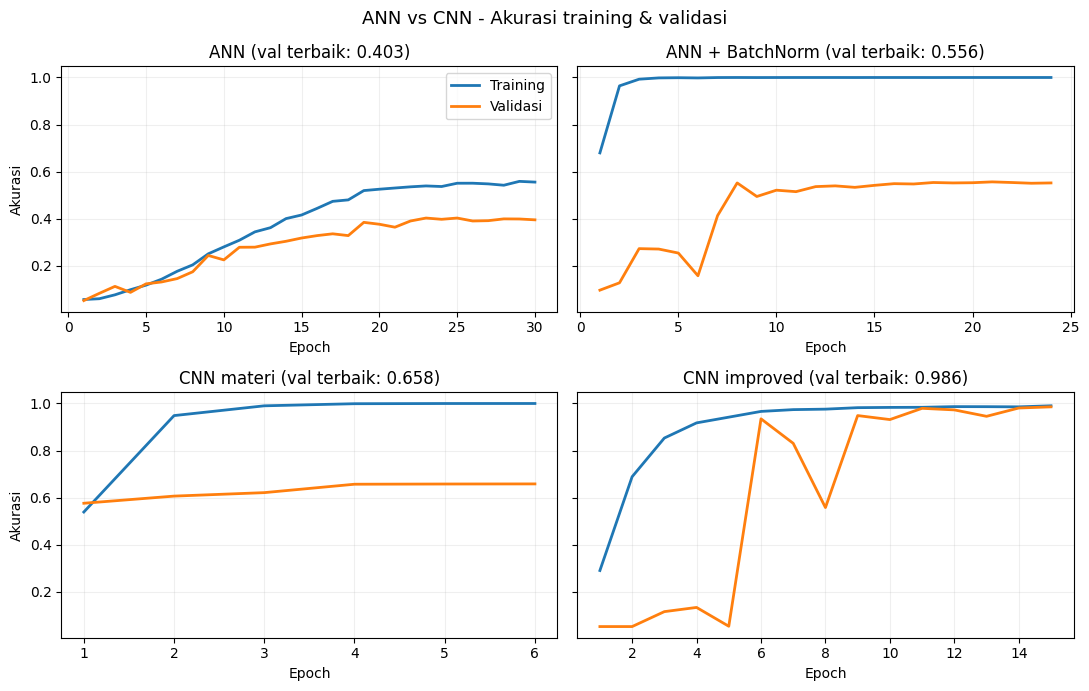

In [42]:
# Perbandingan ANN vs CNN seperti slide kuliah "Loss Comparison of CNN Model and ANN Model"
# Setiap model punya kotak grafik sendiri (training vs validasi), jadi garisnya tidak saling menumpuk.
# Sumbu-y disamakan antar kotak supaya tetap bisa dibandingkan; loss memakai skala log karena
# lonjakan awal (sampai ~25) membuat nilai kecil (~0.1) tidak terlihat.
pembanding = [("E0_ann", "ANN"), ("E0b_ann_bn", "ANN + BatchNorm"),
              ("E1_cnn_lecture", "CNN materi"), ("E2_improved_cnn", "CNN improved")]
pembanding = [(n, l) for n, l in pembanding if n in hists]

for metric, judul, log in [("loss", "Loss", True), ("accuracy", "Akurasi", False)]:
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=True)
    for ax, (name, label) in zip(axes.ravel(), pembanding):
        h = hists[name]
        ep = np.arange(1, len(h[metric]) + 1)
        ax.plot(ep, h[metric], linewidth=2, label="Training")
        ax.plot(ep, h["val_" + metric], linewidth=2, label="Validasi")
        terbaik = min(h["val_" + metric]) if metric == "loss" else max(h["val_" + metric])
        ax.set_title(f"{label} (val terbaik: {terbaik:.3f})")
        ax.set_xlabel("Epoch"); ax.grid(alpha=0.2)
        if log: ax.set_yscale("log")
    for ax in axes.ravel()[len(pembanding):]: ax.axis("off")
    for ax in axes[:, 0]: ax.set_ylabel(judul + (" (skala log)" if log else ""))
    axes[0, 0].legend()
    fig.suptitle(f"ANN vs CNN - {judul} training & validasi", fontsize=13)
    plt.tight_layout(); plt.show()


E1_cnn_lecture pada test -> loss: 1.5281 - acc: 0.5800
label actual: ca | label prediction: ka
label actual: pa | label prediction: wa
label actual: tha | label prediction: tha
label actual: pa | label prediction: pa
label actual: la | label prediction: la
label actual: la | label prediction: sa
label actual: ca | label prediction: ka
label actual: sa | label prediction: sa


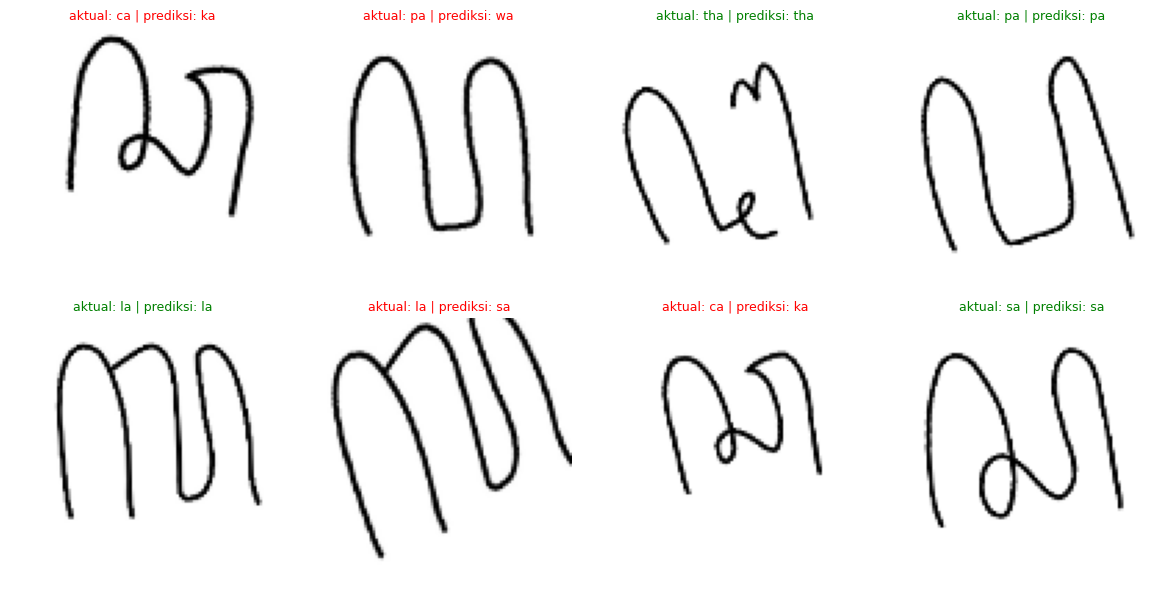

In [43]:
# Load model & prediksi (seperti slide "Load Model CNN dan Prediction")
load_model = keras.models.load_model
path = os.path.join(MODEL_DIR, "E1_cnn_lecture.keras")
if os.path.exists(path):
    model_simpan = load_model(path)
    loss_t, acc_t = model_simpan.evaluate(test_ds, verbose=0)          # seperti model.evaluate(X_test, y_test)
    print(f"E1_cnn_lecture pada test -> loss: {loss_t:.4f} - acc: {acc_t:.4f}")
    idx = np.random.default_rng(SEED).choice(len(P["test"]), 8, replace=False)   # sampel acak
    imgs = np.stack([_load(P["test"][i], 0)[0].numpy() for i in idx])
    pred = model_simpan.predict(imgs, verbose=0)
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for ax, i, p, img in zip(axes.ravel(), idx, pred, imgs):
        a, b = class_names[Y["test"][i]], class_names[int(np.argmax(p))]
        print("label actual:", a, "| label prediction:", b)
        ax.imshow(img.astype("uint8")); ax.axis("off")
        ax.set_title(f"aktual: {a} | prediksi: {b}", color="green" if a == b else "red", fontsize=9)
    plt.tight_layout(); plt.show()

### Model final

Grafik evaluasi model final: S_E2_improved_cnn_seed1


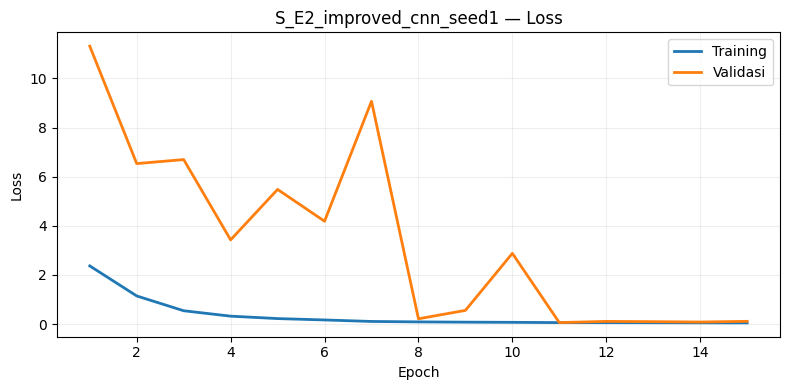

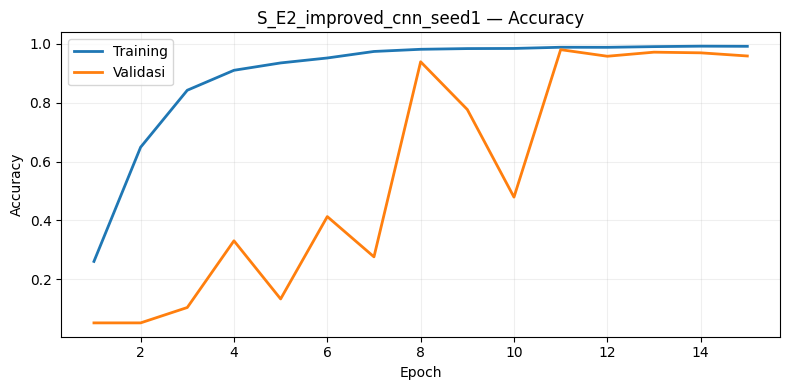

In [44]:
final_model = load_trained(FINAL_NAME)
h = hists[FINAL_NAME]
print(f"Grafik evaluasi model final: {FINAL_NAME}")
tampilkan_kurva_model(FINAL_NAME, h)


S_E2_improved_cnn_seed1 - akurasi test: 0.9508

              precision    recall  f1-score   support

          ba      1.000     1.000     1.000        60
          ca      1.000     0.533     0.696        60
          da      1.000     0.983     0.992        60
         dha      1.000     1.000     1.000        60
          ga      1.000     1.000     1.000        60
          ha      0.667     1.000     0.800        60
          ja      1.000     1.000     1.000        60
          ka      1.000     1.000     1.000        60
          la      1.000     0.583     0.737        60
          ma      1.000     1.000     1.000        60
          na      0.984     1.000     0.992        60
         nga      1.000     1.000     1.000        60
         nya      1.000     1.000     1.000        60
          pa      1.000     1.000     1.000        60
          ra      1.000     1.000     1.000        60
          sa      0.682     1.000     0.811        60
          ta      1.000     0.917

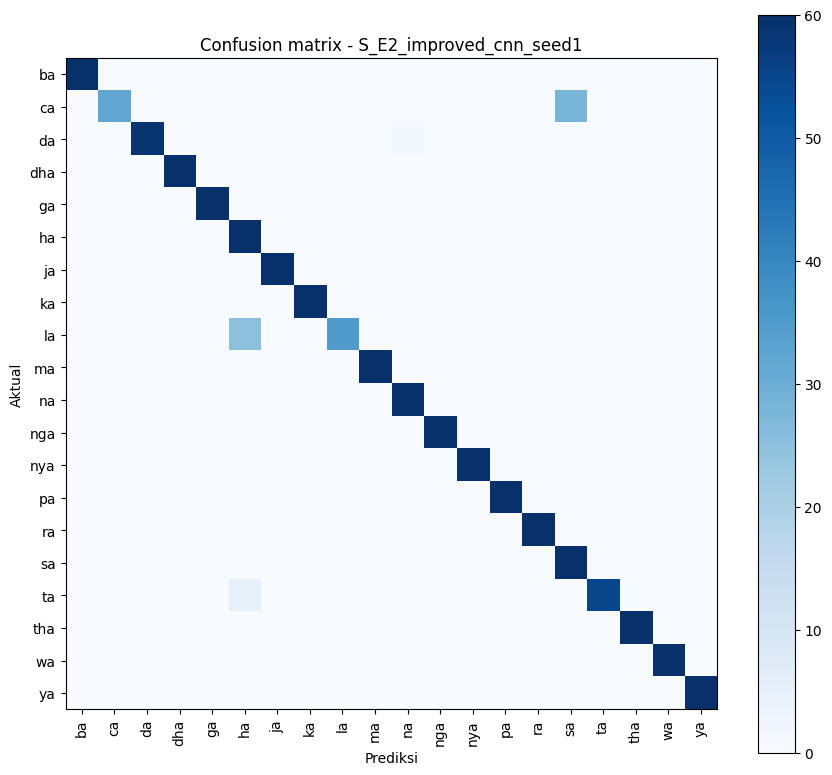

Kesalahan terbanyak (aktual -> prediksi, jumlah):
  ca -> sa: 28
  la -> ha: 25
  ta -> ha: 5
  da -> na: 1


In [45]:
# Evaluasi akhir pada TEST
y_true, y_pred = predict_ds(final_model, test_ds)
print(f"{FINAL_NAME} - akurasi test: {(y_true == y_pred).mean():.4f}\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm, cmap="Blues"); plt.colorbar(im)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(class_names, rotation=90)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(class_names)
ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual"); ax.set_title(f"Confusion matrix - {FINAL_NAME}")
plt.tight_layout(); plt.show()

err_pairs = sorted([(class_names[i], class_names[j], int(cm[i, j])) for i in range(NUM_CLASSES)
                    for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0], key=lambda t: -t[2])
print("Kesalahan terbanyak (aktual -> prediksi, jumlah):")
for a, p, n in err_pairs[:10]: print(f"  {a} -> {p}: {n}")

Model final: S_E2_improved_cnn_seed1


,loss,accuracy
split,,
train,0.0106,0.9994
val,0.0619,0.9799
test,0.1237,0.9508


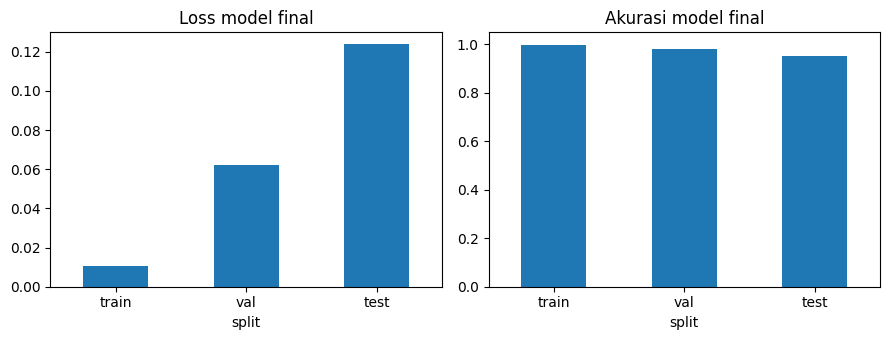

In [46]:
# Loss & accuracy model final di train / val / test (seperti model.evaluate di slide materi)
compile_model(final_model, 1e-3, "adam")   # model hasil load belum di-compile; evaluate butuh loss & metrik (optimizer tidak dipakai)
rows = []
for split, ds in [("train", make_ds(P["train"], Y["train"], cache=False)), ("val", val_ds), ("test", test_ds)]:
    loss_s, acc_s = final_model.evaluate(ds, verbose=0)
    rows.append(dict(split=split, loss=round(loss_s, 4), accuracy=round(acc_s, 4)))
eval_df = pd.DataFrame(rows).set_index("split")
print(f"Model final: {FINAL_NAME}"); display(eval_df)
eval_df.to_csv(os.path.join(OUT_DIR, "final_loss_accuracy.csv"))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
eval_df["loss"].plot(kind="bar", ax=ax[0], title="Loss model final", rot=0)
eval_df["accuracy"].plot(kind="bar", ax=ax[1], title="Akurasi model final", rot=0, ylim=(0, 1.05))
plt.tight_layout(); plt.show()

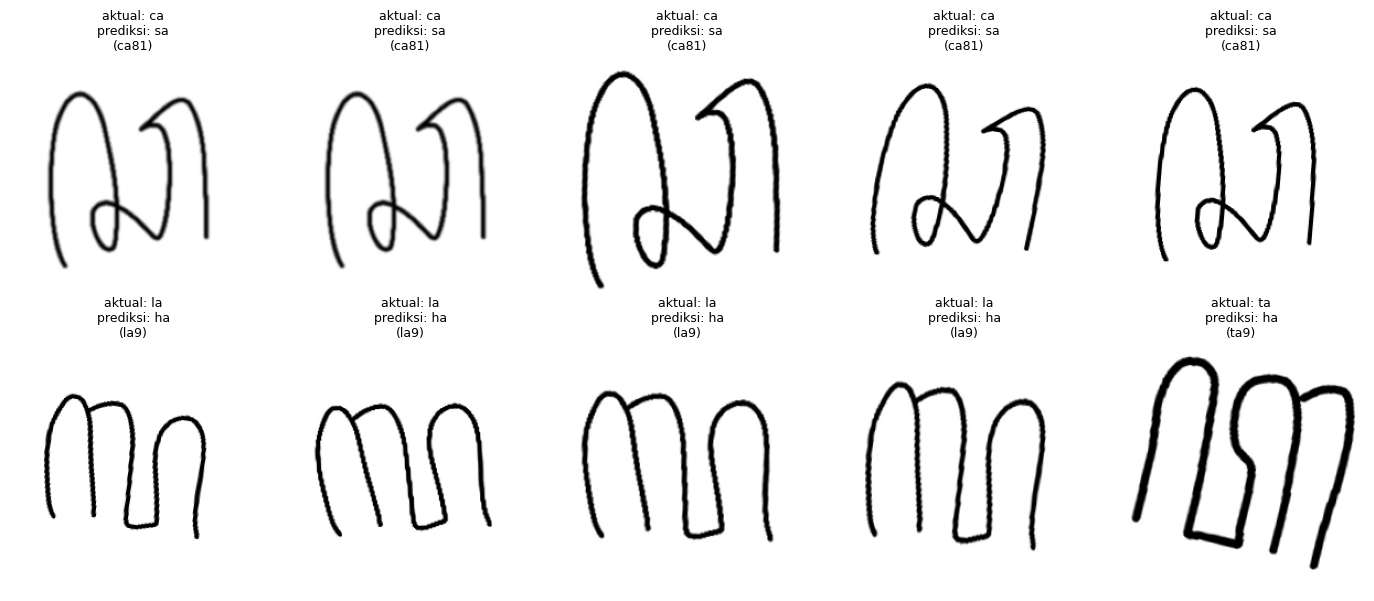

In [47]:
# Contoh gambar yang salah diprediksi (bahan analisis error)
wrong = np.where(y_true != y_pred)[0]
if len(wrong):
    pick = wrong[np.linspace(0, len(wrong) - 1, min(10, len(wrong))).astype(int)]   # tersebar, tidak hanya 1 kelas
    fig, axes = plt.subplots(2, 5, figsize=(14, 6))
    for ax in axes.ravel(): ax.axis("off")
    for ax, i in zip(axes.ravel(), pick):
        ax.imshow(keras.utils.load_img(P["test"][i]))
        ax.set_title(f"aktual: {class_names[y_true[i]]}\nprediksi: {class_names[y_pred[i]]}\n({STEM['test'][i]})", fontsize=9)
    plt.tight_layout(); plt.show()
else:
    print("Tidak ada kesalahan pada test.")

### Evaluasi per tulisan asli
Test berisi 1.200 gambar, tetapi hanya berasal dari 41 tulisan asli. Kesalahan pada satu tulisan cenderung terulang di semua variannya, jadi ukuran sampel efektifnya jauh lebih kecil dari 1.200. Karena itu dihitung juga akurasi per tulisan, voting mayoritas, dan **selang kepercayaan 95%** (bootstrap per tulisan asli).

In [48]:
df_g = pd.DataFrame({"stem": STEM["test"], "true": y_true, "pred": y_pred})
df_g["correct"] = df_g["true"] == df_g["pred"]
g = df_g.groupby("stem").agg(kelas=("true", lambda s: class_names[s.iloc[0]]), n_varian=("correct", "size"),
                             acc=("correct", "mean"), vote=("pred", lambda s: class_names[s.mode().iloc[0]]))
g["vote_benar"] = g["kelas"] == g["vote"]

rng = np.random.default_rng(SEED)
boot = []
for _ in range(2000):
    sub = g.loc[rng.choice(g.index.values, len(g), replace=True)]
    boot.append((sub["acc"] * sub["n_varian"]).sum() / sub["n_varian"].sum())
ci_lo, ci_hi = np.percentile(boot, [2.5, 97.5])

print(f"Gambar test: {len(df_g)} | tulisan asli: {len(g)} | rata-rata {g['n_varian'].mean():.1f} varian per tulisan")
print(f"Akurasi per gambar : {df_g['correct'].mean():.4f}  (95% CI: {ci_lo:.3f} - {ci_hi:.3f})")
print(f"Akurasi per tulisan (voting): {g['vote_benar'].mean():.4f}  ({g['vote_benar'].sum()} dari {len(g)} tulisan dikenali benar)")
print("\nTulisan asli yang tidak sempurna:")
display(g[g["acc"] < 1].sort_values("acc"))
g.to_csv(os.path.join(OUT_DIR, "test_per_source.csv"))

Gambar test: 1200 | tulisan asli: 41 | rata-rata 29.3 varian per tulisan
Akurasi per gambar : 0.9508  (95% CI: 0.879 - 0.999)
Akurasi per tulisan (voting): 0.9512  (39 dari 41 tulisan dikenali benar)

Tulisan asli yang tidak sempurna:


,kelas,n_varian,acc,vote,vote_benar
stem,,,,,
ca81,ca,30,0.066667,sa,False
la9,la,29,0.137931,ha,False
ta9,ta,26,0.807692,ta,True
da84,da,26,0.961538,da,True


## 6. Group Stratified K-Fold (slide 4)
Untuk memastikan hasil tidak bergantung pada satu pembagian data, konfigurasi final dievaluasi dengan **Group Stratified K-Fold** pada gabungan train + val. Grup = tulisan asli, sehingga varian dari tulisan yang sama tidak pernah berada di fold latih dan fold validasi sekaligus. Hasil tiap fold disimpan, jadi bisa dilanjutkan jika terputus.

In [49]:
RUN_KFOLD = True                    # False untuk melewati
N_SPLITS = 3 if CPU_MODE else 5
KFOLD_CSV = os.path.join(OUT_DIR, "kfold_results.csv")

val_full_p, val_full_y = list_split("val")              # val lengkap: grouping sudah mencegah kebocoran
pool_p = np.concatenate([P["train"], val_full_p]); pool_y = np.concatenate([Y["train"], val_full_y])
pool_g = np.array([source_stem(os.path.basename(p)) for p in pool_p])
print(len(pool_p), "gambar,", len(set(pool_g)), "tulisan asli")

def kfold_eval(cfg, n_splits):
    done = pd.read_csv(KFOLD_CSV) if os.path.exists(KFOLD_CSV) else pd.DataFrame()
    skf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    for k, (tr, va) in enumerate(skf.split(pool_p, pool_y, pool_g), 1):
        if len(done) and ((done["config"] == cfg["name"]) & (done["fold"] == k)).any():
            print(f"Fold {k}: sudah ada, dilewati"); continue
        assert not set(pool_g[tr]) & set(pool_g[va])
        t0 = time.time()
        model, _ = train_model(cfg, make_ds(pool_p[tr], pool_y[tr], shuffle=True, cache=False),
                               make_ds(pool_p[va], pool_y[va], cache=False), verbose=0)
        yv, pv = predict_ds(model, make_ds(pool_p[va], pool_y[va], cache=False))
        row = dict(config=cfg["name"], fold=k, acc=float((yv == pv).mean()), f1_macro=f1_score(yv, pv, average="macro"),
                   n_tulisan_val=len(set(pool_g[va])))
        print(f"Fold {k}: acc = {row['acc']:.4f} | f1 = {row['f1_macro']:.4f} | {row['n_tulisan_val']} tulisan val | {time.time() - t0:.0f} s")
        done = pd.DataFrame([row]) if done.empty else pd.concat([done, pd.DataFrame([row])], ignore_index=True)
        done.to_csv(KFOLD_CSV, index=False)
    r = done[done["config"] == cfg["name"]]
    print(f"{cfg['name']}: acc = {r['acc'].mean():.4f} +/- {r['acc'].std():.4f} ({len(r)} fold)")
    return r

if RUN_KFOLD:
    kfold_cfg = {**all_cfgs[FINAL_CONFIG], "seed": SEED, "name": "kfold_" + FINAL_CONFIG}
    print("Group K-Fold untuk:", FINAL_CONFIG, "| n_splits =", N_SPLITS)
    kfold_res = kfold_eval(kfold_cfg, N_SPLITS)

10800 gambar, 345 tulisan asli
Group K-Fold untuk: E2_improved_cnn | n_splits = 3
Fold 1: sudah ada, dilewati
Fold 2: sudah ada, dilewati
Fold 3: sudah ada, dilewati
kfold_E2_improved_cnn: acc = 0.9349 +/- 0.0152 (3 fold)


## 7. Ringkasan untuk slide 7-10
Tabel disimpan ke `output_final/slide_*.csv` agar mudah ditempel ke presentasi. Draf kesimpulan dibuat otomatis dari angka; periksa dan sesuaikan kalimatnya.

In [50]:
res_all = pd.DataFrame(results)
cols = ["name", "arch", "lr", "optimizer", "dropout", "aug", "unfreeze_last", "params", "train_acc", "val_acc", "test_acc", "test_f1_macro", "time_s"]

s7 = res_all[res_all["phase"] == 1][cols].sort_values("val_acc", ascending=False).round(4)
s7["gap_train_val"] = (s7["train_acc"] - s7["val_acc"]).round(4)          # besar = overfitting
s7["best_val_loss"] = [round(min(hists[n]["val_loss"]), 4) if n in hists else None for n in s7["name"]]   # loss validasi terbaik
print("SLIDE 7 - Fase 1: perbandingan arsitektur"); display(s7)
s7.to_csv(os.path.join(OUT_DIR, "slide7_fase1.csv"), index=False)

s8 = res_all[res_all["phase"] == 2][cols].sort_values("val_acc", ascending=False).round(4)
print("SLIDE 8 - Fase 2: random search"); display(s8)
s8.to_csv(os.path.join(OUT_DIR, "slide8_random_search.csv"), index=False)

print("SLIDE 9 - Kestabilan antar seed"); display(summary)
kf_row = None
if os.path.exists(KFOLD_CSV):
    kf = pd.read_csv(KFOLD_CSV); kf = kf[kf["config"] == "kfold_" + FINAL_CONFIG]
    if len(kf):
        kf_row = (kf["acc"].mean(), kf["acc"].std(), len(kf))
        print(f"Group K-Fold {FINAL_CONFIG}: acc {kf_row[0]:.4f} +/- {kf_row[1]:.4f} ({kf_row[2]} fold)")
print(f"Test per tulisan asli: akurasi {df_g['correct'].mean():.4f} (95% CI {ci_lo:.3f}-{ci_hi:.3f}), voting {g['vote_benar'].sum()}/{len(g)} tulisan")
print("Kesalahan terbanyak:", err_pairs[:5])

# ---------- Draf kesimpulan (slide 10) ----------
fin = summary.loc[FINAL_CONFIG]
print("\nSLIDE 10 - Draf kesimpulan:")
print(f"1. Model terbaik: {FINAL_CONFIG} ({fin['arch']}) -> akurasi test {fin['test_mean']:.3f} +/- {fin['test_std']:.3f}, "
      f"F1-macro {fin['f1_mean']:.3f} ({int(fin['n_run'])} seed).")
others = summary.drop(FINAL_CONFIG)
if len(others):
    o = others.iloc[0]; diff = fin["test_mean"] - o["test_mean"]
    same = abs(diff) <= max(fin["test_std"], o["test_std"])
    print(f"2. Pembanding: {others.index[0]} ({o['arch']}, {int(o['params']):,} parameter vs {int(fin['params']):,}) "
          f"-> test {o['test_mean']:.3f} +/- {o['test_std']:.3f}; selisih {diff:+.3f} "
          f"{'masih dalam rentang variasi antar-seed (setara)' if same else 'lebih besar dari variasi antar-seed'}.")
ann_v = s7[s7["arch"].isin(["ann", "ann_bn"])]["val_acc"].max()
lec_v = s7.loc[s7["name"] == "E1_cnn_lecture", "val_acc"]
if len(lec_v):
    imp_v = s7[s7["arch"] == "improved"]["val_acc"].max(); tl_v = s7[s7["arch"] == "mobilenetv2"]["val_acc"].max()
    print(f"3. Validasi fase 1: ANN terbaik {ann_v:.3f} < CNN materi {lec_v.iloc[0]:.3f} < MobileNetV2 {tl_v:.3f} < CNN improved {imp_v:.3f}: "
          "convolution + pooling jauh lebih cocok untuk citra aksara dibanding ANN biasa.")
print(f"4. Evaluasi per tulisan asli: 95% CI {ci_lo:.3f}-{ci_hi:.3f}; kesalahan terpusat pada "
      f"{', '.join(f'{a}->{p}' for a, p, _ in err_pairs[:3]) if err_pairs else '-'} (bentuk huruf mirip).")
if kf_row:
    print(f"5. Group K-Fold ({kf_row[2]} fold): {kf_row[0]:.3f} +/- {kf_row[1]:.3f} vs validasi {fin['val_mean']:.3f} -> "
          f"{'hasil konsisten di pembagian data lain' if abs(kf_row[0] - fin['val_mean']) <= 2 * max(kf_row[1], 0.01) else ('angka validasi split bawaan agak optimis; pada pembagian lain akurasinya lebih rendah' if kf_row[0] < fin['val_mean'] else 'pada pembagian lain akurasinya justru lebih tinggi')}.")
print("6. Keterbatasan: training di CPU (96x96, epoch dibatasi), test hanya 41 tulisan asli. "
      "Saran: GPU 224x224, lebih banyak penulis berbeda, coba ResNet/EfficientNet.")

SLIDE 7 - Fase 1: perbandingan arsitektur


,name,arch,lr,optimizer,dropout,aug,unfreeze_last,params,train_acc,val_acc,test_acc,test_f1_macro,time_s,gap_train_val,best_val_loss
3,E2_improved_cnn,improved,0.0010,adam,0.5,False,NaN,425332,0.9902,0.9857,0.9575,0.9559,2775,0.0045,0.0595
5,E7_mobilenetv2_finetune,mobilenetv2,0.0010,adam,0.3,False,30.0,2283604,0.9923,0.9196,0.9350,0.9341,1792,0.0727,0.2372
4,E6_mobilenetv2_frozen,mobilenetv2,0.0010,adam,0.3,False,NaN,2283604,0.9292,0.8767,0.8808,0.8798,1089,0.0525,0.4564
2,E1_cnn_lecture,lecture,0.0010,adam,0.0,False,NaN,1186100,1.0000,0.5762,0.5800,0.5638,103,0.4238,1.4640
1,E0b_ann_bn,ann_bn,0.0010,adam,0.3,False,NaN,3182612,1.0000,0.5520,0.5983,0.5808,202,0.4480,1.6465
0,E0_ann,ann,0.0001,adam,0.3,False,NaN,3181460,0.5587,0.3953,0.4058,0.3919,193,0.1634,2.0133


SLIDE 8 - Fase 2: random search


,name,arch,lr,optimizer,dropout,aug,unfreeze_last,params,train_acc,val_acc,test_acc,test_f1_macro,time_s
6,R_E2_improved_cnn_t1,improved,0.0030,adam,0.2,True,NaN,425332,0.9802,0.9678,0.9583,0.9566,2708
7,R_E2_improved_cnn_t2,improved,0.0003,adam,0.5,False,NaN,425332,0.9840,0.9665,0.9783,0.9785,2619
9,R_E2_improved_cnn_t4,improved,0.0030,sgd,0.2,True,NaN,425332,0.9239,0.9634,0.9400,0.9392,2622
11,R_E7_mobilenetv2_finetune_t2,mobilenetv2,0.0001,adam,0.5,False,60.0,2283604,0.9526,0.9147,0.9125,0.9132,1937
12,R_E7_mobilenetv2_finetune_t3,mobilenetv2,0.0030,sgd,0.5,True,20.0,2283604,0.8819,0.8897,0.8892,0.8899,1947
10,R_E7_mobilenetv2_finetune_t1,mobilenetv2,0.0001,adam,0.2,True,60.0,2283604,0.9474,0.8723,0.8567,0.8527,1908
13,R_E7_mobilenetv2_finetune_t4,mobilenetv2,0.0300,sgd,0.2,False,30.0,2283604,0.8858,0.8633,0.8242,0.8087,1708
8,R_E2_improved_cnn_t3,improved,0.0300,sgd,0.2,False,NaN,425332,0.9904,0.7003,0.7583,0.7376,2905


SLIDE 9 - Kestabilan antar seed


,arch,params,n_run,val_mean,val_std,test_mean,test_std,f1_mean,f1_std
config,,,,,,,,,
E2_improved_cnn,improved,425332,3,0.9792,0.0013,0.9594,0.0171,0.9585,0.0178
E7_mobilenetv2_finetune,mobilenetv2,2283604,3,0.9382,0.0003,0.9300,0.0254,0.9289,0.0256


Group K-Fold E2_improved_cnn: acc 0.9349 +/- 0.0152 (3 fold)
Test per tulisan asli: akurasi 0.9508 (95% CI 0.879-0.999), voting 39/41 tulisan
Kesalahan terbanyak: [('ca', 'sa', 28), ('la', 'ha', 25), ('ta', 'ha', 5), ('da', 'na', 1)]

SLIDE 10 - Draf kesimpulan:
1. Model terbaik: E2_improved_cnn (improved) -> akurasi test 0.959 +/- 0.017, F1-macro 0.959 (3 seed).
2. Pembanding: E7_mobilenetv2_finetune (mobilenetv2, 2,283,604 parameter vs 425,332) -> test 0.930 +/- 0.025; selisih +0.029 lebih besar dari variasi antar-seed.
3. Validasi fase 1: ANN terbaik 0.552 < CNN materi 0.576 < MobileNetV2 0.920 < CNN improved 0.986: convolution + pooling jauh lebih cocok untuk citra aksara dibanding ANN biasa.
4. Evaluasi per tulisan asli: 95% CI 0.879-0.999; kesalahan terpusat pada ca->sa, la->ha, ta->ha (bentuk huruf mirip).
5. Group K-Fold (3 fold): 0.935 +/- 0.015 vs validasi 0.979 -> angka validasi split bawaan agak optimis; pada pembagian lain akurasinya lebih rendah.
6. Keterbatasan: training

## 8. Simpan model final

In [51]:
shutil.copy(os.path.join(MODEL_DIR, f"{FINAL_NAME}.weights.h5"), os.path.join(OUT_DIR, "best_model.weights.h5"))
json.dump(all_cfgs[FINAL_NAME], open(os.path.join(OUT_DIR, "best_cfg.json"), "w"), indent=2)
print("Tersimpan:", FINAL_NAME, "->", os.path.join(OUT_DIR, "best_model.weights.h5"))

Tersimpan: S_E2_improved_cnn_seed1 -> D:\aksara_jawa\output_final\best_model.weights.h5


## Simpan semua tabel dan grafik terbaru
Sel ini menyimpan semua tabel hasil ke `output_final/tabel`, loss dan accuracy per epoch setiap model ke `output_final/history_per_epoch`, lalu menampilkan daftar grafik yang tersimpan di `output_final/figures`.

In [52]:
# === Simpan SEMUA tabel terbaru ke CSV ===
TAB_DIR = os.path.join(OUT_DIR, "tabel")
HIST_DIR = os.path.join(OUT_DIR, "history_per_epoch")
for d in (TAB_DIR, HIST_DIR):
    shutil.rmtree(d, ignore_errors=True); os.makedirs(d, exist_ok=True)

def simpan(df, nama, index=False):
    path = os.path.join(TAB_DIR, f"{nama}.csv")
    df.to_csv(path, index=index)
    print(f"  {nama}.csv  ({len(df)} baris)")

print("Tabel ->", TAB_DIR)
simpan(pd.DataFrame(results), "semua_eksperimen")
if "df_counts" in globals(): simpan(df_counts, "jumlah_per_kelas", index=True)
if "arch_df" in globals():   simpan(arch_df, "arsitektur")
if "s7" in globals():        simpan(s7, "fase1_perbandingan_arsitektur")
if "s8" in globals():        simpan(s8, "fase2_random_search")
if "summary" in globals():   simpan(summary, "fase3_seed_summary", index=True)
if "eval_df" in globals():   simpan(eval_df, "final_loss_accuracy", index=True)
if "y_true" in globals():
    rep = pd.DataFrame(classification_report(y_true, y_pred, target_names=class_names, digits=4, output_dict=True)).T
    simpan(rep.round(4), "classification_report", index=True)
    simpan(pd.DataFrame(cm, index=class_names, columns=class_names), "confusion_matrix", index=True)
    simpan(pd.DataFrame(err_pairs, columns=["aktual", "prediksi", "jumlah"]), "kesalahan_terbanyak")
if "g" in globals():         simpan(g, "test_per_tulisan_asli", index=True)
if os.path.exists(KFOLD_CSV): simpan(pd.read_csv(KFOLD_CSV), "kfold_results")

# Loss & accuracy per epoch untuk setiap model (bahan grafik kurva belajar)
print("History per epoch ->", HIST_DIR)
for name, h in hists.items():
    n = len(h["loss"])
    df_h = pd.DataFrame({k: v for k, v in h.items() if len(v) == n})
    df_h.insert(0, "epoch", range(1, n + 1))
    df_h.to_csv(os.path.join(HIST_DIR, f"{name}.csv"), index=False)
print(f"  {len(hists)} file history")

print("\nGrafik ->", FIG_DIR)
for f in sorted(os.listdir(FIG_DIR)): print("  ", f)

Tabel -> D:\aksara_jawa\output_final\tabel
  semua_eksperimen.csv  (20 baris)
  jumlah_per_kelas.csv  (20 baris)
  arsitektur.csv  (5 baris)
  fase1_perbandingan_arsitektur.csv  (6 baris)
  fase2_random_search.csv  (8 baris)
  fase3_seed_summary.csv  (2 baris)
  final_loss_accuracy.csv  (3 baris)
  classification_report.csv  (23 baris)
  confusion_matrix.csv  (20 baris)
  kesalahan_terbanyak.csv  (4 baris)
  test_per_tulisan_asli.csv  (41 baris)
  kfold_results.csv  (3 baris)
History per epoch -> D:\aksara_jawa\output_final\history_per_epoch
  20 file history

Grafik -> D:\aksara_jawa\output_final\figures
   01_jumlah_gambar_per_kelas_per_split.png
   02_ba.png
   03_fase_1_ann_akurasi_validasi_dan_test.png
   04_fase_1_cnn_akurasi_validasi_dan_test.png
   05_fase_1_transfer_learning_akurasi_validasi_dan_test.png
   06_e0b_ann_bn_loss.png
   07_e0b_ann_bn_accuracy.png
   08_e0_ann_loss.png
   09_e0_ann_accuracy.png
   10_e2_improved_cnn_loss.png
   11_e2_improved_cnn_accuracy.png
   12

## 9. Referensi (slide 12)
1. Dataset: *Javanese Script (Aksara Jawa) Augmented*, Kaggle, oleh hannanhunafa (salin URL dari halaman dataset).
2. Afiahayati. *Introduction to Deep Learning* (slide kuliah), Departemen Ilmu Komputer dan Elektronika, Universitas Gadjah Mada.
3. LeCun, Y., Bengio, Y., & Hinton, G. (2015). Deep learning. *Nature*, 521, 436-444.
4. Krizhevsky, A., Sutskever, I., & Hinton, G. (2012). ImageNet classification with deep convolutional neural networks. *NIPS 2012*.
5. Sandler, M., Howard, A., Zhu, M., Zhmoginov, A., & Chen, L.-C. (2018). MobileNetV2: Inverted residuals and linear bottlenecks. *CVPR 2018*.
6. Ioffe, S., & Szegedy, C. (2015). Batch normalization: Accelerating deep network training by reducing internal covariate shift. *ICML 2015*.
7. Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. *JMLR*, 15, 1929-1958.
8. Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *ICLR 2015*.
9. Chollet, F., et al. Keras; Abadi, M., et al. (2016). TensorFlow: A system for large-scale machine learning. *OSDI 2016*.